# **NOTES:**
I ran this notebook in VSCODE with python 3.13.7 btw, so if irurun niyo ito sa google colab, baka magka-error. so yeah just a heads up :) meron din mga libs here na need muna i install bago nyo i run pero kaya nyo yan <3>

In [ ]:
from datasets import load_dataset
from IPython.display import display

ds = load_dataset("SilencioNetwork/cebuano-speech")

print(ds)  # Shows available splits and their sizes
split = next(iter(ds))  # Select the first available split
display(ds[split].to_pandas().head(90))

c:\Users\casper\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    test: Dataset({
        features: ['audio', 'speaker_id', 'language', 'transcript', 'transcript_type', 'gender', 'country', 'mother_tongue', 'dialect', 'os', 'device', 'duration', 'script_type', 'words', 'n_words', 'transcript_model', 'aligner', 'age_band', 'native_speaker', 'proficiency'],
        num_rows: 90
    })
})


,audio,speaker_id,language,transcript,transcript_type,gender,country,mother_tongue,dialect,os,device,duration,script_type,words,n_words,transcript_model,aligner,age_band,native_speaker,proficiency
0,{'bytes': b'RIFF\xa4\x93\x90\x01WAVEfmt \x10\x...,CEB_008,Cebuano,Niadto ako og picnic niadto miaging bulan sa u...,human_validated,male,Philippines,Tagalog / Filipino,Philippines - Manila (Tagalog),Linux,Mobile,136.73,free_speech,"[{'text': 'Niadto', 'normalized_text': 'Niadto...",219,human,wav2vec2_mms,45-59,False,fluent
1,{'bytes': b'RIFF$\xe3\x0c\x01WAVEfmt \x10\x00\...,CEB_008,Cebuano,Ang pulong dululanan kasagarang gigamit sa Pil...,human_validated,male,Philippines,Tagalog / Filipino,Philippines - Manila (Tagalog),Linux,Mobile,91.78,free_speech,"[{'text': 'Ang', 'normalized_text': 'Ang', 'st...",138,human,wav2vec2_mms,45-59,False,fluent
2,{'bytes': b'RIFF\xa4\xcb\x0c\x02WAVEfmt \x10\x...,CEB_008,Cebuano,Kanus-a ang imong adlaw natawhan? Usa kini sa ...,human_validated,male,Philippines,Tagalog / Filipino,Philippines - Manila (Tagalog),Linux,Mobile,179.13,free_speech,"[{'text': 'Kanus-a', 'normalized_text': 'Kanus...",260,human,wav2vec2_mms,45-59,False,fluent
3,{'bytes': b'RIFF\xa4\x9bY\x03WAVEfmt \x10\x00\...,CEB_008,Cebuano,"Sa modernong panahon, halos tanan nato napugos...",human_validated,male,Philippines,Tagalog / Filipino,Philippines - Manila (Tagalog),Linux,Mobile,292.73,free_speech,"[{'text': 'Sa', 'normalized_text': 'Sa', 'star...",475,human,wav2vec2_mms,45-59,False,fluent
4,{'bytes': b'RIFF$\xea\xaa\x01WAVEfmt \x10\x00\...,CEB_008,Cebuano,"Sa atong adlaw-adlaw nga kinabuhi, ang kwarta ...",human_validated,male,Philippines,Tagalog / Filipino,Philippines - Manila (Tagalog),Linux,Mobile,145.72,free_speech,"[{'text': 'Sa', 'normalized_text': 'Sa', 'star...",216,human,wav2vec2_mms,45-59,False,fluent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,{'bytes': b'RIFF$\xf6\x8f\x01WAVEfmt \x10\x00\...,CEB_004,Cebuano,Kung mangutana ang usa ka tawo kung unsa kong ...,human_validated,male,Philippines,English,Philippines - Visayan English,Linux,Desktop,136.52,free_speech,"[{'text': 'Kung', 'normalized_text': 'Kung', '...",305,human,wav2vec2_mms,18-24,True,native
86,{'bytes': b'RIFF\xa4y\x9b\x01WAVEfmt \x10\x00\...,CEB_004,Cebuano,"Karong adlawa, sayo ko ning mata aron makapad-...",human_validated,male,Philippines,English,Philippines - Visayan English,Linux,Desktop,140.45,free_speech,"[{'text': 'Karong', 'normalized_text': 'Karong...",308,human,wav2vec2_mms,18-24,True,native
87,{'bytes': b'RIFF$\xb3x\x01WAVEfmt \x10\x00\x00...,CEB_004,Cebuano,"Kung moadto ko sa merkado, kasagaran akong pal...",human_validated,male,Philippines,English,Philippines - Visayan English,Linux,Desktop,128.58,free_speech,"[{'text': 'Kung', 'normalized_text': 'Kung', '...",262,human,wav2vec2_mms,18-24,True,native
88,{'bytes': b'RIFF$.\x94\x01WAVEfmt \x10\x00\x00...,CEB_004,Cebuano,"Oo, kanunay ko nga maglakaw kon adunay higayon...",human_validated,male,Philippines,English,Philippines - Visayan English,Linux,Desktop,137.96,free_speech,"[{'text': 'Oo,', 'normalized_text': 'Oo,', 'st...",299,human,wav2vec2_mms,18-24,True,native


# **Data Acquisition and EDA**

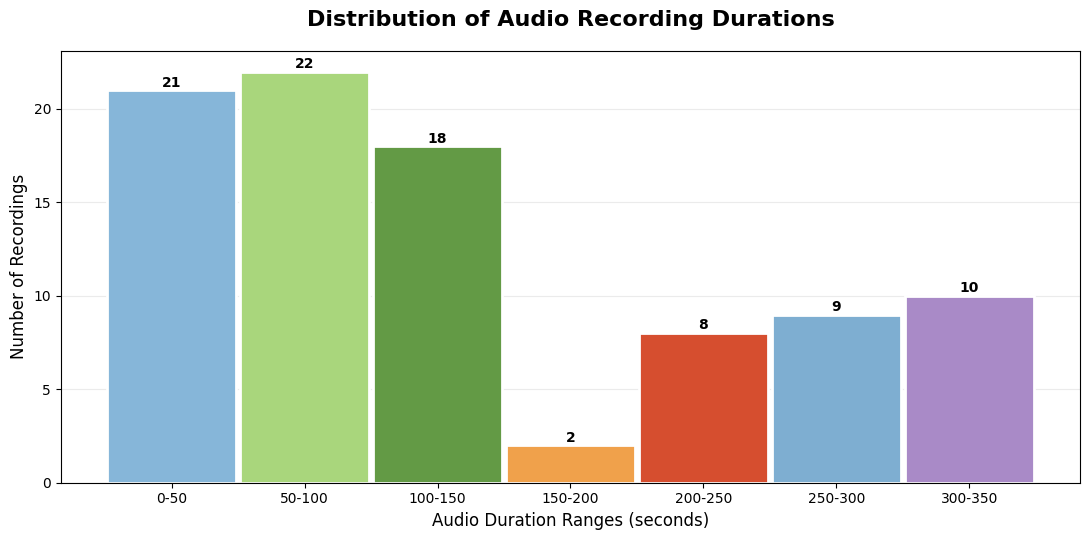

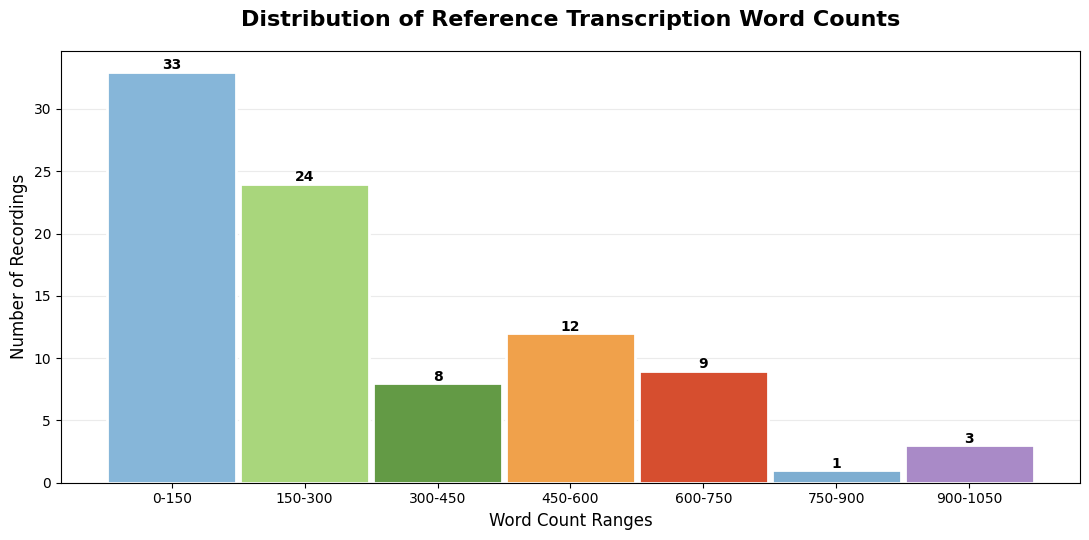

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = ds[next(iter(ds))].to_pandas()

df["duration"] = pd.to_numeric(
    df["duration"], errors="coerce"
)
df["n_words"] = pd.to_numeric(
    df["n_words"], errors="coerce"
)

# Plotting function
def colorful_histogram(data, bins, title, xlabel, filename):

    values = data.dropna()

    # Count values within each bin
    counts, edges = np.histogram(values, bins=bins)

    # Create readable range labels
    labels = [
        f"{int(edges[i])}-{int(edges[i+1])}"
        for i in range(len(edges)-1)
    ]

    # Color palette
    colors = [
        "#86B6D9",
        "#A9D67C",
        "#639A45",
        "#F0A14B",
        "#D64E2F",
        "#7EAED1",
        "#A98AC7",
        "#E6C567"
    ]

    fig, ax = plt.subplots(figsize=(11, 5.5))

    bars = ax.bar(
        labels,
        counts,
        color=colors[:len(counts)],
        edgecolor="white",
        linewidth=2,
        width=0.97
    )

    # Add count labels above bars
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.2,
            str(int(height)),
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel("Number of Recordings", fontsize=12)

    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# FIGURE 1: Audio Duration
colorful_histogram(
    df["duration"],
    bins=[0, 50, 100, 150, 200, 250, 300, 350],
    title="Distribution of Audio Recording Durations",
    xlabel="Audio Duration Ranges (seconds)",
    filename="duration_histogram.png"
)

# FIGURE 2: Word Count
colorful_histogram(
    df["n_words"],
    bins=[0, 150, 300, 450, 600, 750, 900, 1050],
    title="Distribution of Reference Transcription Word Counts",
    xlabel="Word Count Ranges",
    filename="word_count_histogram.png"
)


#**Determining the longest audio recording and  the audio with the highest word  Count and vice versa**

In [ ]:
import pandas as pd

records = ds[split].to_pandas()
max_n_words = records.loc[records["n_words"].idxmax()]
max_duration = records.loc[records["duration"].idxmax()]
min_n_words = records.loc[records["n_words"].idxmin()]
min_duration = records.loc[records["duration"].idxmin()]

maxima = pd.DataFrame([
    {
        "Highest by": "n_words",
        "Row": max_n_words.name,
        "Speaker ID": max_n_words["speaker_id"],
        "n_words": max_n_words["n_words"],
        "duration (s)": max_n_words["duration"],
    },
    {
        "Highest by": "duration",
        "Row": max_duration.name,
        "Speaker ID": max_duration["speaker_id"],
        "n_words": max_duration["n_words"],
        "duration (s)": max_duration["duration"],
    },
])


minima = pd.DataFrame([
    {
        "Lowest by": "n_words",
        "Row": min_n_words.name,
        "Speaker ID": min_n_words["speaker_id"],
        "n_words": min_n_words["n_words"],
        "duration (s)": min_n_words["duration"],
    },
    {
        "Lowest by": "duration",
        "Row": min_duration.name,
        "Speaker ID": min_duration["speaker_id"],
        "n_words": min_duration["n_words"],
        "duration (s)": min_duration["duration"],
    },
])



display(maxima)
display(minima)


,Highest by,Row,Speaker ID,n_words,duration (s)
0,n_words,15,CEB_007,957,300.00
1,duration,39,CEB_001,503,300.37


,Lowest by,Row,Speaker ID,n_words,duration (s)
0,n_words,71,CEB_006,57,30.13
1,duration,68,CEB_006,66,30.10


# **Exporting the shortest Audio File**

In [ ]:
from pathlib import Path

speaker_records = records.loc[records["speaker_id"].eq("CEB_006")] #you can change the speaker ID to any other speaker in the dataset
if speaker_records.empty:
    raise ValueError("No records found for speaker CEB_006")

selected = speaker_records.loc[speaker_records["duration"].idxmin()]
record_index = int(selected.name)
audio_data = selected["audio"]
if not isinstance(audio_data, dict) or "bytes" not in audio_data:
    raise ValueError("The selected record does not contain raw audio bytes.")
audio_bytes = audio_data.get("bytes")
if audio_bytes is None:
    raise ValueError("Audio bytes are not available for the selected record")

audio_output = Path("CEB_006_lowest_duration.wav") #if amgpapalit kau ng filename, make sure to update the display message below accordingly
audio_output.write_bytes(audio_bytes)
print(
    f"Saved row {record_index} for CEB_006 "
    f"({selected['n_words']} words, {selected['duration']} seconds) to {audio_output.resolve()}"
)

Saved row 68 for CEB_006 (66 words, 30.1 seconds) to D:\digisig\final project\ceb_audio\CEB_006_lowest_duration.wav


#**Exporting the Transcript File**
do not skip kasi need to for the WER Comparison

In [ ]:

from pathlib import Path
import pandas as pd

# STEP 1: Find records belonging to CEB_006
speaker_records = records.loc[
    records["speaker_id"].eq("CEB_006")
]

if speaker_records.empty:
    raise ValueError("No records found for speaker CEB_006")

# STEP 2: Select the shortest recording
selected = speaker_records.loc[
    speaker_records["duration"].idxmin()
]

record_index = int(selected.name)

print("Selected Record")
print("-" * 45)
print("Speaker ID:", selected["speaker_id"])
print("Record Index:", record_index)
print("Duration:", selected["duration"])
print("Word Count:", selected["n_words"])

# STEP 3: Identify the transcription column
possible_columns = [
    "transcript",
]

transcript_column = next(
    (
        col for col in possible_columns
        if col in records.columns
    ),
    None
)

if transcript_column is None:
    raise ValueError(
        "Transcription column not found. "
        f"Available columns: {records.columns.tolist()}"
    )

# STEP 4: Extract the matching transcription
reference_text = selected[transcript_column]

if pd.isna(reference_text) or not str(reference_text).strip():
    raise ValueError("Reference transcription is empty.")

reference_text = str(reference_text).strip()

# STEP 5: Export as TXT
output_path = Path("CEB_006_reference.txt")

output_path.write_text(
    reference_text,
    encoding="utf-8"
)

# STEP 6: Display results
print("\nREFERENCE TRANSCRIPTION")
print("-" * 45)
print(reference_text)

print("\nTranscript Column:", transcript_column)
print("Saved to:", output_path.resolve())


Selected Record
---------------------------------------------
Speaker ID: CEB_006
Record Index: 68
Duration: 30.1
Word Count: 66

REFERENCE TRANSCRIPTION
---------------------------------------------
Naa ka bay anting-anting? Wala. Wala koy anting-anting kay kaning anting-anting mang gud,usa ni siya ka dakong sala sa Kristiyanismo. Kay ang anting-anting mangod murag nisalig ka sa imuhang anting-anting kaysa sa imong Ginoo nga imong Diyos. Kaning anting-anting kay gibuhat ni siya sa yawa nga motintal bitaw nga kani ang imong saligan dapat instead nga ang Ginoo. So wala koy anting-anting, bad kay na siya.

Transcript Column: transcript
Saved to: D:\digisig\final project\ceb_audio\CEB_006_reference.txt


#**Characteristics of the 3 Audios**
Since yung characteristics nung 3 audio are different from one another, need natin i standardized muna before augmenting it

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path

# STEP 1: Locate audio files
audio_folder = Path("noisy_audio")

audio_files = {
    "Original Cebuano Speech": "CEB_006_lowest_duration.wav",
    "Train Noise": "train_noise.mp3",
    "Street Noise": "street_noise.mp3",
    "Talking Noise": "talking_noise.mp3"
}

# Planned SNR levels
target_snr_levels = [15,0]

# STEP 2: Analyze recordings
results = []

for audio_type, filename in audio_files.items():

    path = audio_folder / filename

    if not path.exists():
        print(f"File not found: {path}")
        continue

    # Load audio directly
    audio, sr = sf.read(path, dtype="float64")

    # Record original channel count
    channels = 1 if audio.ndim == 1 else audio.shape[1]

    # Convert to mono for level analysis
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    # Calculate duration
    duration = len(audio) / sr

    # Calculate RMS amplitude
    rms = np.sqrt(np.mean(audio ** 2))

    # RMS level in dBFS
    rms_dbfs = 20 * np.log10(max(rms, 1e-12))

    # Peak amplitude
    peak = np.max(np.abs(audio))

    # Target SNR is an experimental setting
    target_snr = (
        ", ".join(map(str, target_snr_levels))
        if audio_type != "Original Cebuano Speech"
        else "N/A"
    )

    results.append({
        "Audio Type": audio_type,
        "Sampling Rate (Hz)": sr,
        "Duration (s)": round(duration, 2),
        "Channels": channels,
        "Target SNR (dB)": target_snr,
        "RMS Level (dBFS)": round(rms_dbfs, 2),
        "Peak Amplitude": round(peak, 4)
    })

# STEP 3: Display results
df_characteristics = pd.DataFrame(results)

print("\nAUDIO CHARACTERISTICS SUMMARY")
print("-" * 90)

print(df_characteristics.to_string(index=False))

# STEP 4: Export to CSV
output_path = Path("audio_characteristics.csv")

df_characteristics.to_csv(
    output_path,
    index=False
)

print("\nSaved to:", output_path.resolve())



AUDIO CHARACTERISTICS SUMMARY
------------------------------------------------------------------------------------------
             Audio Type  Sampling Rate (Hz)  Duration (s)  Channels Target SNR (dB)  RMS Level (dBFS)  Peak Amplitude
Original Cebuano Speech               48000         30.10         2             N/A            -18.47          1.0000
            Train Noise               24000        256.63         2           15, 0            -15.11          1.2758
           Street Noise               44100        419.89         2           15, 0            -14.00          1.0493
          Talking Noise               48000        253.20         1           15, 0            -20.64          0.9274

Saved to: D:\digisig\final project\ceb_audio\audio_characteristics.csv


# **Standardizing the Audios**

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
from math import gcd
from pathlib import Path

# STEP 1: Define audio files
audio_folder = Path("noisy_audio")

audio_files = {
    "Original Cebuano Speech": "CEB_006_lowest_duration.wav",
    "Train Noise": "train_noise.mp3",
    "Street Noise": "street_noise.mp3",
    "Talking Noise": "talking_noise.mp3"
}

# STEP 2: Define standardization settings
target_sr = 16000

# Folder for standardized recordings
output_folder = Path("standardized_audio")
output_folder.mkdir(parents=True, exist_ok=True)

# STEP 3: Function to calculate audio characteristics
def get_characteristics(audio, sr):

    channels = 1 if audio.ndim == 1 else audio.shape[1]

    # Use mono representation for RMS and peak analysis
    mono = (
        audio.mean(axis=1)
        if audio.ndim == 2
        else audio
    )

    rms = np.sqrt(np.mean(mono ** 2))
    rms_dbfs = (
        20 * np.log10(rms)
        if rms > 0
        else float("-inf")
    )

    peak = np.max(np.abs(mono))
    duration = len(mono) / sr

    return {
        "Sampling Rate (Hz)": sr,
        "Channels": channels,
        "Duration (s)": round(duration, 2),
        "RMS Level (dBFS)": round(rms_dbfs, 2),
        "Peak Amplitude": round(peak, 4)
    }

# STEP 4: Standardize each recording
results = []

for audio_type, filename in audio_files.items():

    input_path = audio_folder / filename

    if not input_path.exists():
        raise FileNotFoundError(
            f"Audio file not found: {input_path}"
        )

    # Load original recording
    audio, sr = sf.read(
        input_path,
        dtype="float64"
    )

    # Measure original characteristics
    before = get_characteristics(audio, sr)

    # Convert stereo to mono
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    # Resample to 16 kHz
    if sr != target_sr:

        divisor = gcd(sr, target_sr)

        audio = resample_poly(
            audio,
            up=target_sr // divisor,
            down=sr // divisor
        )

    # Measure standardized characteristics
    after = get_characteristics(audio, target_sr)

    # Save standardized audio
    output_name = (
        Path(filename).stem + "_standardized.wav"
    )

    output_path = output_folder / output_name

    # FLOAT preserves amplitudes without PCM clipping
    sf.write(
        output_path,
        audio,
        target_sr,
        subtype="FLOAT"
    )

    # Record before and after characteristics
    results.append({
        "Audio Type": audio_type,
        "Standardized SR (Hz)": after["Sampling Rate (Hz)"],
        "Standardized Channels": after["Channels"],
        "Standardized Duration (s)": after["Duration (s)"],
        "Standardized RMS (dBFS)": after["RMS Level (dBFS)"],
        "Standardized Peak": after["Peak Amplitude"]
    })

    print(f"Standardized: {filename}")
    print(f"Saved to: {output_path}")
    print("-" * 50)

# STEP 5: Create comparison table
df_standardized = pd.DataFrame(results)

print("\nAUDIO STANDARDIZATION RESULTS")
print("=" * 80)

print(df_standardized.to_string(index=False))

# STEP 6: Export results to CSV
csv_path = Path("audio_standardization_comparison.csv")

df_standardized.to_csv(
    csv_path,
    index=False
)

print("\nComparison table saved to:", csv_path.resolve())
print("Standardization completed successfully!")


Standardized: CEB_006_lowest_duration.wav
Saved to: standardized_audio\CEB_006_lowest_duration_standardized.wav
--------------------------------------------------
Standardized: train_noise.mp3
Saved to: standardized_audio\train_noise_standardized.wav
--------------------------------------------------
Standardized: street_noise.mp3
Saved to: standardized_audio\street_noise_standardized.wav
--------------------------------------------------
Standardized: talking_noise.mp3
Saved to: standardized_audio\talking_noise_standardized.wav
--------------------------------------------------

AUDIO STANDARDIZATION RESULTS
             Audio Type  Standardized SR (Hz)  Standardized Channels  Standardized Duration (s)  Standardized RMS (dBFS)  Standardized Peak
Original Cebuano Speech                 16000                      1                      30.10                   -18.47             1.0179
            Train Noise                 16000                      1                     256.63        

# **Audio Mixing Process (AUGMENTATION)**

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path

# STEP 1: Define folders and files
input_folder = Path("standardized_audio")
output_folder = Path("augmented_audio")
output_folder.mkdir(parents=True, exist_ok=True)

speech_path = input_folder / "CEB_006_lowest_duration_standardized.wav"

noise_files = {
    "train": input_folder / "train_noise_standardized.wav",
    "street": input_folder / "street_noise_standardized.wav",
    "talking": input_folder / "talking_noise_standardized.wav"
}

target_snr_levels = [15, 0]
target_sr = 16000

# STEP 2: Load and validate audio
def load_audio(path):
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    audio, sr = sf.read(path, dtype="float64")

    if sr != target_sr:
        raise ValueError(f"{path.name} is not 16 kHz.")

    if audio.ndim != 1:
        raise ValueError(f"{path.name} is not mono.")

    if len(audio) == 0:
        raise ValueError(f"{path.name} is empty.")

    return audio

speech = load_audio(speech_path)

# STEP 3: Match noise duration to speech
def match_duration(noise, target_length):
    """
    Use the first part of the noise recording.
    If too short, repeat it to match speech duration.
    """
    if len(noise) >= target_length:
        return noise[:target_length].copy()

    repetitions = int(np.ceil(target_length / len(noise)))
    return np.tile(noise, repetitions)[:target_length]

# STEP 4: Calculate signal power
def signal_power(audio):
    return np.mean(audio ** 2)

speech_power = signal_power(speech)

if speech_power <= 0:
    raise ValueError("Speech signal has zero power.")

# STEP 5: Generate augmented audio
results = []

for noise_name, noise_path in noise_files.items():

    noise = load_audio(noise_path)

    noise_segment = match_duration(
        noise,
        len(speech)
    )

    noise_power = signal_power(noise_segment)

    if noise_power <= 0:
        raise ValueError(f"{noise_name} has zero power.")

    for target_snr in target_snr_levels:

        # Calculate noise scaling factor
        alpha = np.sqrt(
            speech_power /
            (
                noise_power *
                10 ** (target_snr / 10)
            )
        )

        # Scale noise
        scaled_noise = noise_segment * alpha

        # Mix speech and noise
        mixed_audio = speech + scaled_noise

        # Calculate achieved SNR
        achieved_snr = 10 * np.log10(
            signal_power(speech) /
            signal_power(scaled_noise)
        )

        # Prevent clipping with common gain
        peak_before = np.max(np.abs(mixed_audio))

        gain = (
            min(1.0, 0.99 / peak_before)
            if peak_before > 0
            else 1.0
        )

        mixed_audio = mixed_audio * gain

        # Calculate output characteristics
        output_rms = np.sqrt(signal_power(mixed_audio))
        output_rms_dbfs = 20 * np.log10(
            max(output_rms, 1e-12)
        )

        output_peak = np.max(np.abs(mixed_audio))

        # Save augmented recording
        filename = (
            f"CEB_006_{noise_name}_{target_snr}dB.wav"
        )

        output_path = output_folder / filename

        sf.write(
            output_path,
            mixed_audio,
            target_sr,
            subtype="FLOAT"
        )

        # Record results
        results.append({
            "Noise Type": noise_name,
            "Target SNR (dB)": target_snr,
            "Achieved SNR (dB)": round(achieved_snr, 2),
            "Noise Scaling Factor": round(alpha, 6),
            "Output Gain": round(gain, 6),
            "Output RMS (dBFS)": round(output_rms_dbfs, 2),
            "Output Peak": round(output_peak, 4),
            "Filename": filename
        })

        print(
            f"Saved: {filename} | "
            f"Achieved SNR: {achieved_snr:.2f} dB"
        )

# STEP 6: Create and export results table
df_results = pd.DataFrame(results)

print("\nDATA AUGMENTATION RESULTS")
print("=" * 85)
print(df_results.to_string(index=False))

csv_path = Path("augmentation_results.csv")

df_results.to_csv(
    csv_path,
    index=False
)

print("\nData augmentation completed!")
print("Output folder:", output_folder.resolve())
print("Results table:", csv_path.resolve())


Saved: CEB_006_train_15dB.wav | Achieved SNR: 15.00 dB
Saved: CEB_006_train_0dB.wav | Achieved SNR: -0.00 dB
Saved: CEB_006_street_15dB.wav | Achieved SNR: 15.00 dB
Saved: CEB_006_street_0dB.wav | Achieved SNR: 0.00 dB
Saved: CEB_006_talking_15dB.wav | Achieved SNR: 15.00 dB
Saved: CEB_006_talking_0dB.wav | Achieved SNR: -0.00 dB

DATA AUGMENTATION RESULTS
Noise Type  Target SNR (dB)  Achieved SNR (dB)  Noise Scaling Factor  Output Gain  Output RMS (dBFS)  Output Peak                 Filename
     train               15               15.0              0.097572     0.973915             -18.56         0.99   CEB_006_train_15dB.wav
     train                0               -0.0              0.548690     0.883117             -16.53         0.99    CEB_006_train_0dB.wav
    street               15               15.0              0.132884     0.954166             -18.74         0.99  CEB_006_street_15dB.wav
    street                0                0.0              0.747259     0.828758    

# **Spectrogram of the Three Noises with the selected CEB Audio**

The two SNR levels na napili ko is 15 dB and 0dB from RRLs na nabasa ko. yung 0 dB means 1:1 ratio sila so like equal power yung signal (aka yung speech), and yung noise. 15 dB is mas malakas yung signal kesa yung noise. Nasa paper na naman natin yun if you want more details

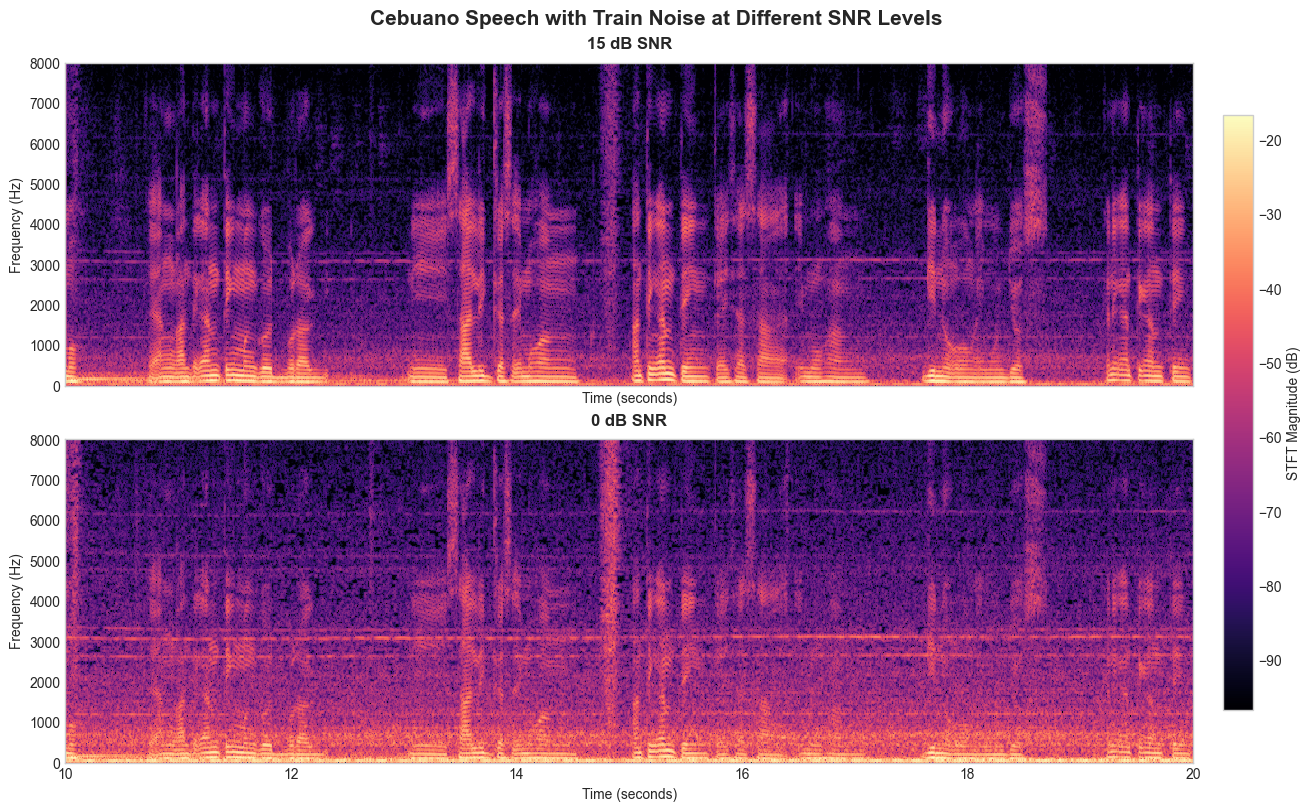

Saved: D:\digisig\final project\ceb_audio\results\train_snr_spectrogram_comparison.png


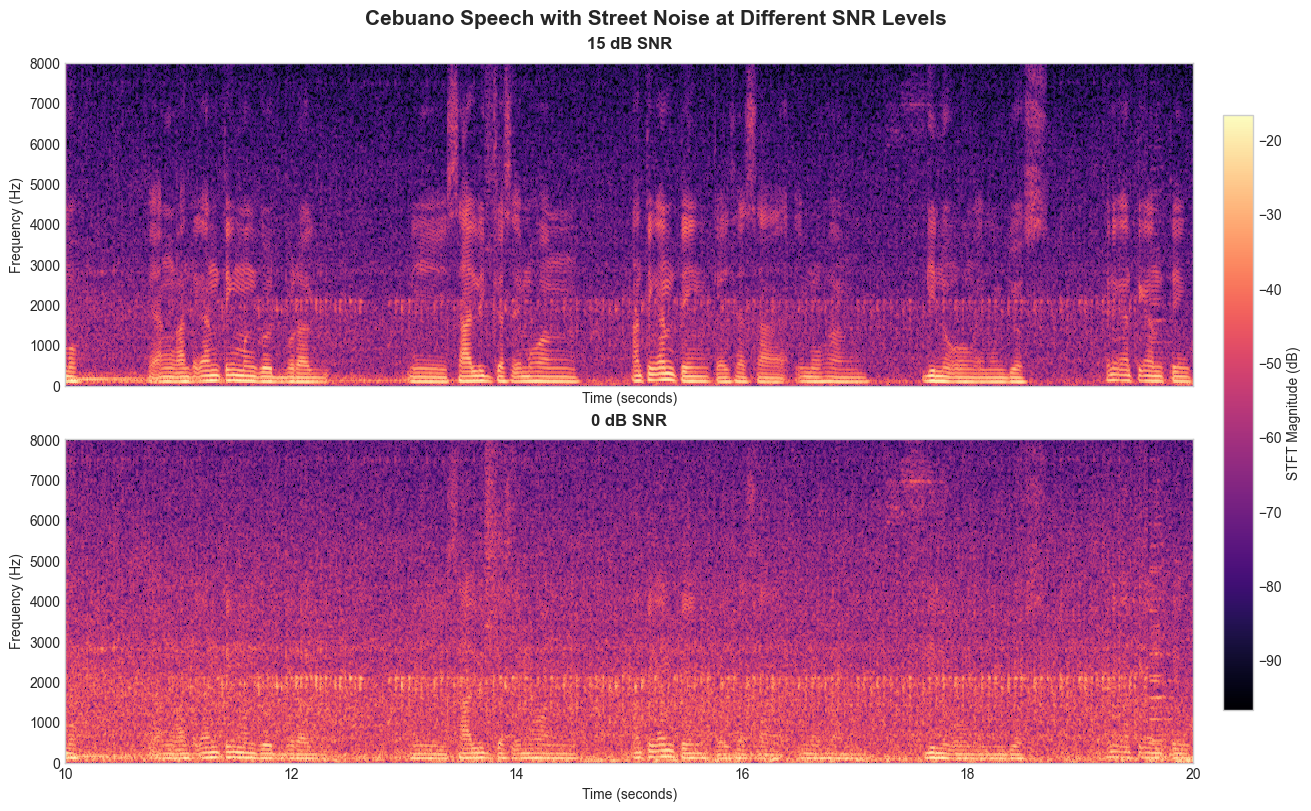

Saved: D:\digisig\final project\ceb_audio\results\street_snr_spectrogram_comparison.png


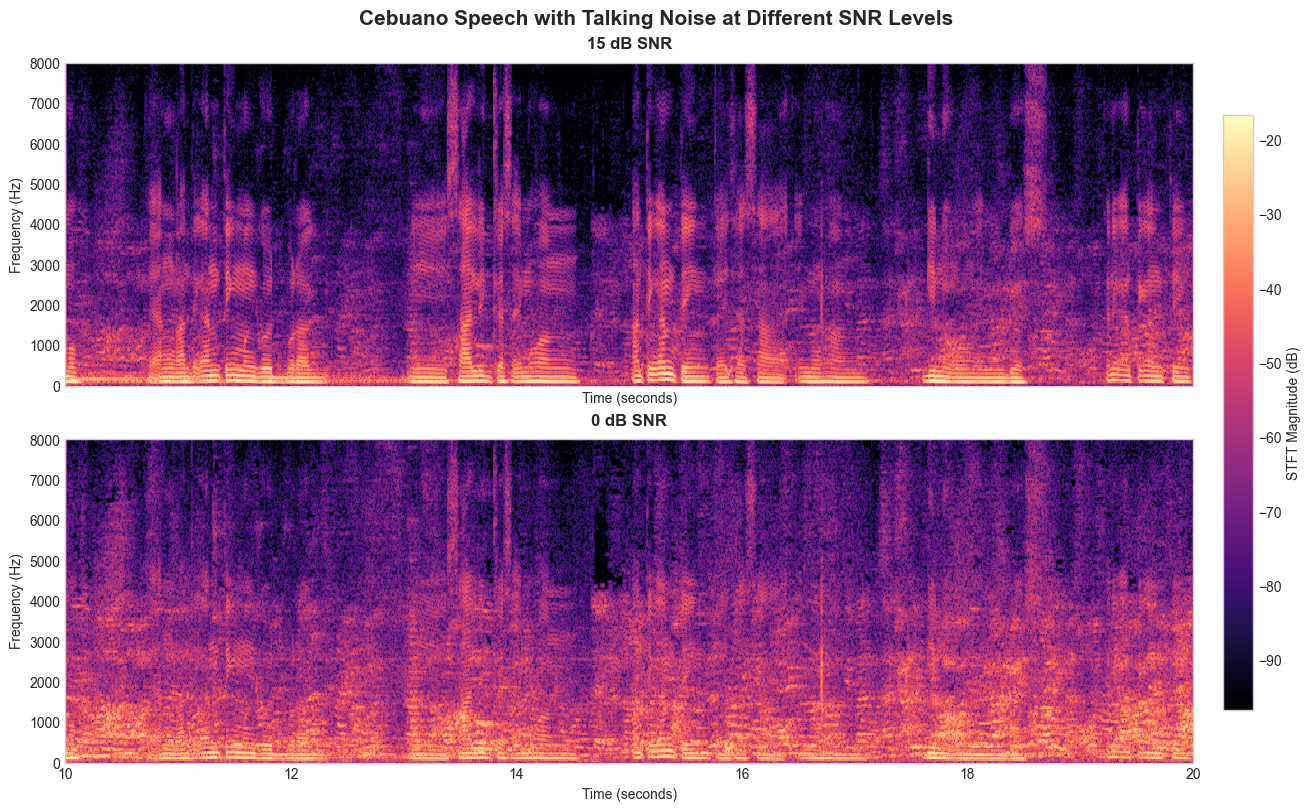

Saved: D:\digisig\final project\ceb_audio\results\talking_snr_spectrogram_comparison.png


In [ ]:

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft
from pathlib import Path

# STEP 1: Define folders and settings
input_folder = Path("augmented_audio")
output_folder = Path("results")
output_folder.mkdir(parents=True, exist_ok=True)

noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

# Select the same 10-second interval for every plot
start_time = 10
duration = 10

# STFT parameters
nperseg = 512
noverlap = 384

# STEP 2: Load and calculate spectrograms
all_spectrograms = {}

for noise_type in noise_types:
    all_spectrograms[noise_type] = {}

    for snr in snr_levels:
        filename = f"CEB_006_{noise_type}_{snr}dB.wav"
        path = input_folder / filename

        if not path.exists():
            raise FileNotFoundError(f"Missing file: {path}")

        audio, sr = sf.read(path)

        if audio.ndim == 2:
            audio = audio.mean(axis=1)

        # Extract the same audio interval
        start_sample = int(start_time * sr)
        end_sample = int((start_time + duration) * sr)

        segment = audio[start_sample:end_sample]

        if len(segment) == 0:
            raise ValueError(f"Empty segment: {filename}")

        # Compute Short-Time Fourier Transform
        frequencies, times, Zxx = stft(
            segment,
            fs=sr,
            nperseg=nperseg,
            noverlap=noverlap
        )

        # Convert STFT magnitude to decibels
        magnitude_db = 20 * np.log10(
            np.maximum(np.abs(Zxx), 1e-10)
        )

        all_spectrograms[noise_type][snr] = (
            frequencies,
            times + start_time,
            magnitude_db
        )

# STEP 3: Use a common color scale across all figures
all_values = [
    spec[2]
    for noise_specs in all_spectrograms.values()
    for spec in noise_specs.values()
]

vmax = max(spec.max() for spec in all_values)
vmin = vmax - 80

# STEP 4: Generate one 2x2 figure per noise type
plt.style.use("seaborn-v0_8-whitegrid")

for noise_type in noise_types:

    fig, axes = plt.subplots(
        2, 1,
        figsize=(13, 8),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    for ax, snr in zip(axes.flat, snr_levels):

        frequencies, times, magnitude_db = (
            all_spectrograms[noise_type][snr]
        )

        image = ax.pcolormesh(
            times,
            frequencies,
            magnitude_db,
            shading="auto",
            cmap="magma",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(
            f"{snr} dB SNR",
            fontsize=12,
            fontweight="bold",
            pad=10
        )

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Frequency (Hz)")
        ax.set_ylim(0, 8000)
        ax.set_xlim(start_time, start_time + duration)

        ax.grid(False)

    # Shared colorbar
    fig.colorbar(
        image,
        ax=axes,
        label="STFT Magnitude (dB)",
        shrink=0.85,
        pad=0.02
    )

    # Figure title
    fig.suptitle(
        f"Cebuano Speech with {noise_type.title()} Noise "
        f"at Different SNR Levels",
        fontsize=15,
        fontweight="bold"
    )

    # Save figure
    output_path = (
        output_folder /
        f"{noise_type}_snr_spectrogram_comparison.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path.resolve()}")


# **EXPERIMENTING ON DIFFERENT THRESHOLDS**
This is just my experimentation lang ng mga thresholds from bandpass hanggang wiener filter so this is really open for changes

Eto yung whisper AI model na ginamit ko: https://huggingface.co/sapinsapin/whisper-small-pld-ceb

pero I reccomend using this 100% kase mas mababa WER kesa yung ginamit ko: https://huggingface.co/sapinsapin/whisper-large-v3-pld-ceb-norm
Kapos lang kasi ako ng space kaya ginamit ko yung isang model wahehhee

if you wanna test the model without downloading it pwede nyo gamitin to: https://huggingface.co/spaces/sapinsapin/halohalo-dashboard

***Kung ako sainyo....i feel like ulitin nalang to waheheheh***

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt, welch, sosfreqz
from pathlib import Path

# ==========================================================
# STEP 1: SETTINGS YOU CAN EXPERIMENT WITH
# ==========================================================

input_folder = Path("augmented_audio")
output_folder = Path("band-pass")
output_folder.mkdir(parents=True, exist_ok=True)

# Noise types and SNR conditions
noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

# ----------------------------------------------------------
# TINKER HERE: BAND-PASS FILTER PARAMETERS
# ----------------------------------------------------------

lowcut = 150      # Lower cutoff frequency (Hz)
highcut = 6000     # Upper cutoff frequency (Hz)
filter_order = 4   # Butterworth filter order

# Suggested experimental settings:
#
# Trial 1: 100 - 7000 Hz, order 4
# Trial 2: 150 - 6000 Hz, order 4
# Trial 3: 300 - 3400 Hz, order 4
#
# These are candidate settings, not established optimal
# parameters. Evaluate them using WER and signal metrics.
#
# Higher filter orders create sharper transitions but
# may also introduce additional signal-processing effects.

# ----------------------------------------------------------
# TINKER HERE: FREQUENCY FIGURE SETTINGS
# ----------------------------------------------------------

nperseg = 2048       # Frequency resolution for Welch PSD
plot_max_freq = 8000 # Maximum frequency displayed (Hz)

# ==========================================================
# STEP 2: DEFINE THE BAND-PASS FILTER
# ==========================================================

def apply_bandpass(audio, sr, lowcut, highcut, order):

    nyquist = sr / 2

    if not (0 < lowcut < highcut < nyquist):
        raise ValueError(
            "Cutoff frequencies must satisfy "
            "0 < lowcut < highcut < Nyquist frequency."
        )

    # Design Butterworth band-pass filter
    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=sr,
        output="sos"
    )

    # Zero-phase forward-backward filtering
    filtered = sosfiltfilt(sos, audio)

    return filtered, sos

# ==========================================================
# STEP 3: PROCESS ALL SIX AUGMENTED RECORDINGS
# ==========================================================

results = []

for noise_type in noise_types:

    for snr in snr_levels:

        filename = f"CEB_006_{noise_type}_{snr}dB.wav"
        input_path = input_folder / filename

        if not input_path.exists():
            raise FileNotFoundError(
                f"Missing audio file: {input_path}"
            )

        # Load augmented audio
        audio, sr = sf.read(input_path, dtype="float64")

        if audio.ndim != 1:
            raise ValueError(
                f"{filename} must be mono."
            )

        if sr != 16000:
            raise ValueError(
                f"{filename} must have a 16 kHz sampling rate."
            )

        # Apply band-pass filtering
        filtered_audio, sos = apply_bandpass(
            audio,
            sr,
            lowcut,
            highcut,
            filter_order
        )

        # Check for output clipping
        peak = np.max(np.abs(filtered_audio))

        if peak > 0.99:
            output_gain = 0.99 / peak
        else:
            output_gain = 1.0

        filtered_audio = filtered_audio * output_gain

        # --------------------------------------------------
        # STEP 4: SAVE FILTERED AUDIO
        # --------------------------------------------------

        # Include noise type to prevent overwriting files.
        output_name = (
            f"CEB006-{noise_type}-{snr}dB-BPF.wav"
        )

        output_path = output_folder / output_name

        sf.write(
            output_path,
            filtered_audio,
            sr,
            subtype="FLOAT"
        )

        # --------------------------------------------------
        # STEP 7: RECORD RESULTS
        # --------------------------------------------------

        results.append({
            "Noise Type": noise_type,
            "SNR (dB)": snr,
            "Lower Cutoff (Hz)": lowcut,
            "Upper Cutoff (Hz)": highcut,
            "Filter Order": filter_order,
            "Output Gain": round(output_gain, 6),
            "Output Peak": round(
                np.max(np.abs(filtered_audio)), 4
            ),
            "Output File": output_name
        })

        print(f"Saved audio: {output_path}")
        print(f"Saved figure: {figure_path}")
        print("-" * 55)

# ==========================================================
# STEP 8: EXPORT PROCESSING SUMMARY
# ==========================================================

df_results = pd.DataFrame(results)

print("\nBAND-PASS FILTERING RESULTS")
print("=" * 75)
print(df_results.to_string(index=False))

csv_path = output_folder / "bandpass_results.csv"

df_results.to_csv(csv_path, index=False)

print("\nProcessing completed successfully!")
print("Output folder:", output_folder.resolve())


Saved audio: band-pass\CEB006-train-15dB-BPF.wav
Saved figure: band-pass\CEB006-talking-0dB-BPF-spectrum.png
-------------------------------------------------------
Saved audio: band-pass\CEB006-train-0dB-BPF.wav
Saved figure: band-pass\CEB006-talking-0dB-BPF-spectrum.png
-------------------------------------------------------
Saved audio: band-pass\CEB006-street-15dB-BPF.wav
Saved figure: band-pass\CEB006-talking-0dB-BPF-spectrum.png
-------------------------------------------------------
Saved audio: band-pass\CEB006-street-0dB-BPF.wav
Saved figure: band-pass\CEB006-talking-0dB-BPF-spectrum.png
-------------------------------------------------------
Saved audio: band-pass\CEB006-talking-15dB-BPF.wav
Saved figure: band-pass\CEB006-talking-0dB-BPF-spectrum.png
-------------------------------------------------------
Saved audio: band-pass\CEB006-talking-0dB-BPF.wav
Saved figure: band-pass\CEB006-talking-0dB-BPF-spectrum.png
-------------------------------------------------------

BAND-P

**CHOOSING THE OPTIMAL THRESHOLD FOR BAND PASS FILTERING**

Processing: CEB_006_train_15dB.wav
Target SNR: 15 dB


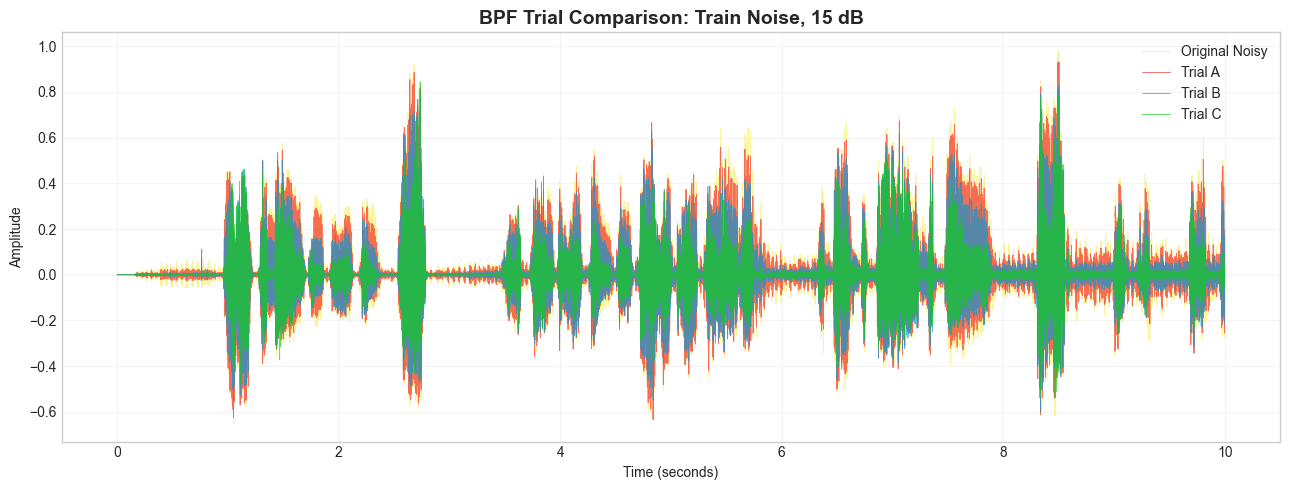

Processing: CEB_006_train_0dB.wav
Target SNR: 0 dB


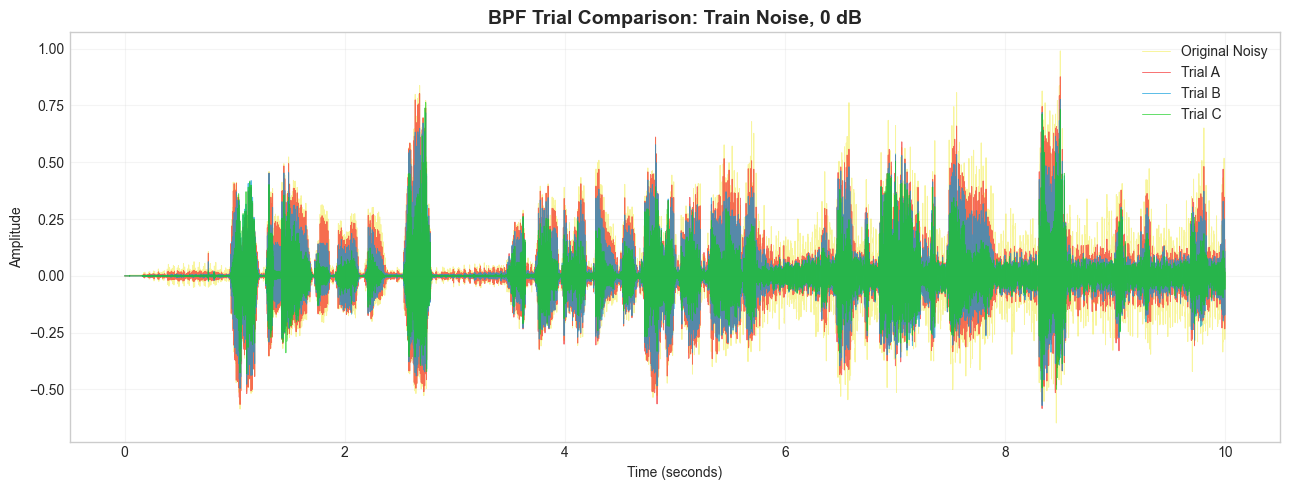

Processing: CEB_006_street_15dB.wav
Target SNR: 15 dB


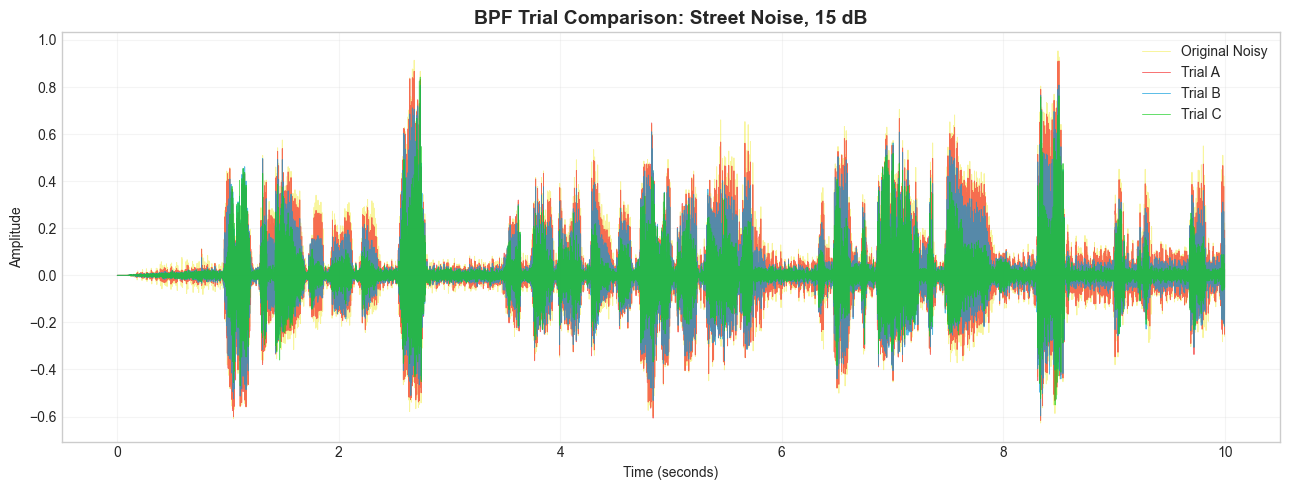

Processing: CEB_006_street_0dB.wav
Target SNR: 0 dB


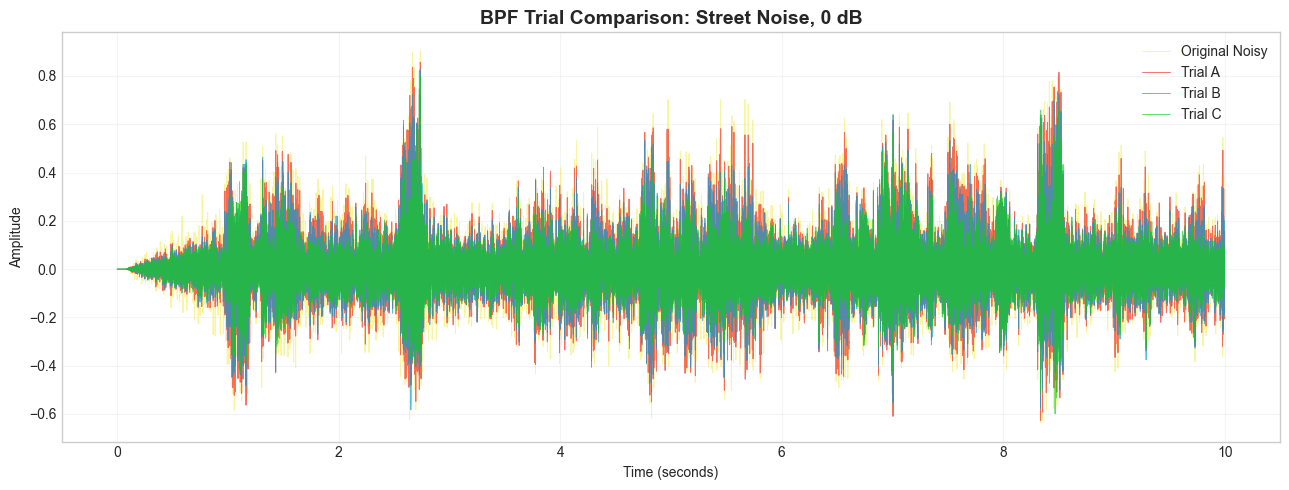

Processing: CEB_006_talking_15dB.wav
Target SNR: 15 dB


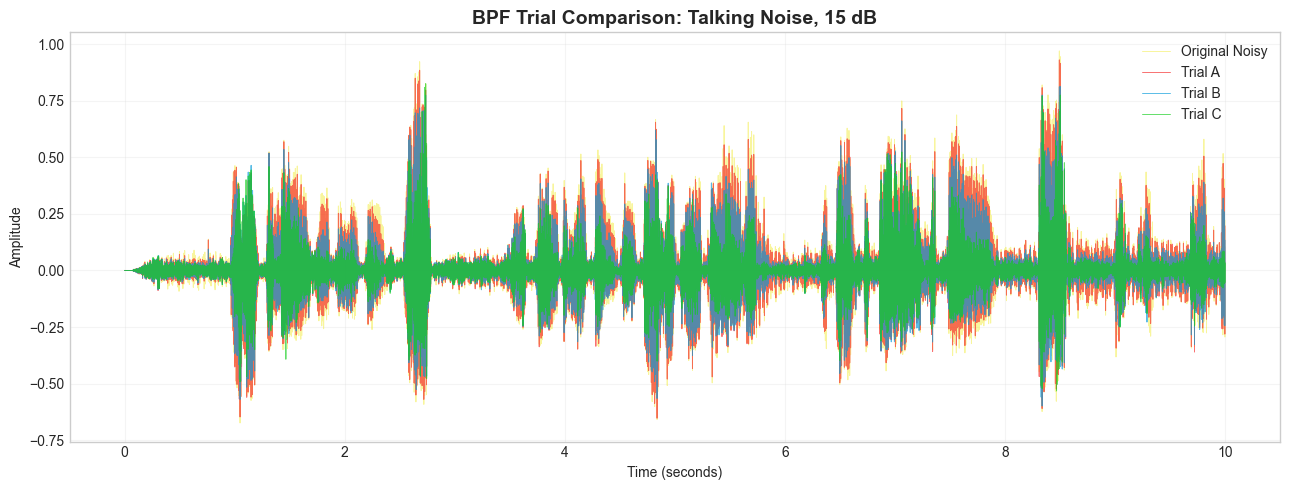

Processing: CEB_006_talking_0dB.wav
Target SNR: 0 dB


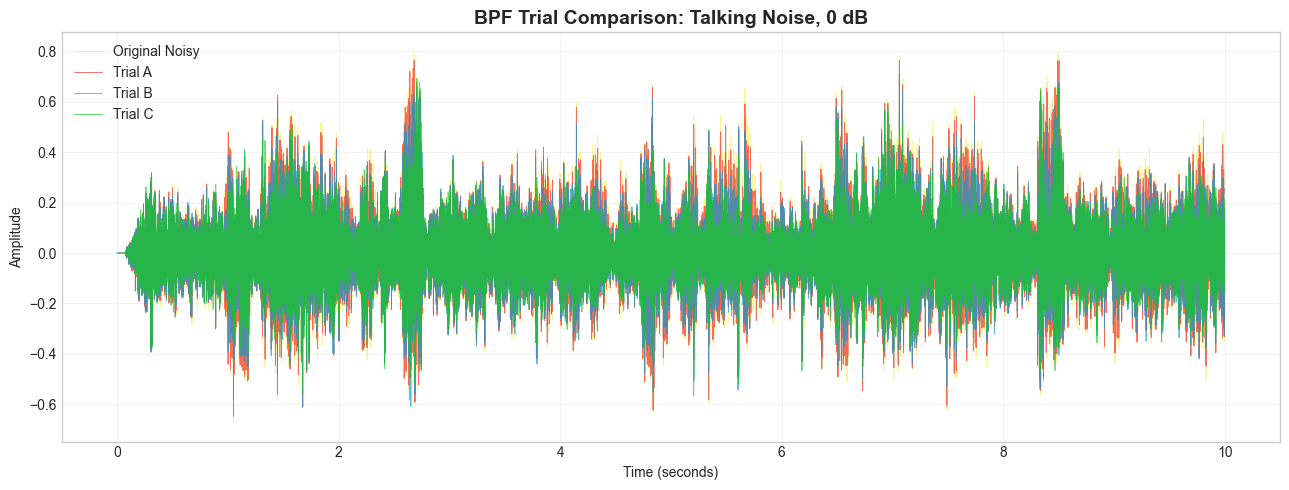


BAND-PASS FILTER TRIAL RESULTS
Noise Type  Input SNR (dB) Trial  Output SNR (dB)  SNR Improvement (dB)  Speech Retention (%)  Speech NRMSE
     train              15     A           23.176                 8.041                75.534         0.229
     train              15     B           21.914                 6.779                46.695         0.640
     train              15     C           19.330                 4.195                19.166         0.862
     train               0     A            9.168                 8.161                75.534         0.229
     train               0     B            7.870                 6.864                46.695         0.640
     train               0     C            5.239                 4.232                19.166         0.862
    street              15     A           15.539                 0.443                75.534         0.229
    street              15     B           14.519                -0.576                46.695         0.

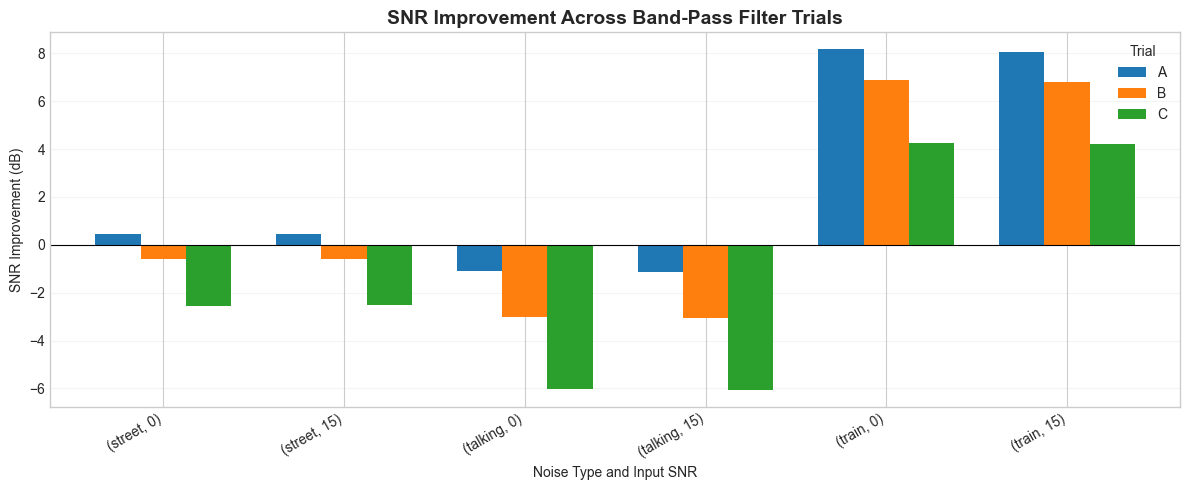


No trial met the speech retention threshold.
Review the results before selecting a filter.


In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt
from pathlib import Path

# ==========================================================
# STEP 1: EXPERIMENTAL SETTINGS
# ==========================================================

input_folder = Path("augmented_audio")
reference_folder = Path("standardized_audio")
output_folder = Path("band-pass")

output_folder.mkdir(parents=True, exist_ok=True)

speech_path = (
    reference_folder /
    "CEB_006_lowest_duration_standardized.wav"
)

noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

target_sr = 16000

# ----------------------------------------------------------
# TINKER HERE: FILTER CONFIGURATIONS
# ----------------------------------------------------------

trials = {
    "A": {"lowcut": 100, "highcut": 7000, "order": 4},
    "B": {"lowcut": 150, "highcut": 6000, "order": 4},
    "C": {"lowcut": 300, "highcut": 3400, "order": 4}
}

# ----------------------------------------------------------
# TINKER HERE: FIGURE SETTINGS
# ----------------------------------------------------------

start_time = 0
duration = 10

# Display every Nth sample for waveform readability
plot_step = 10

colors = {
    "Original": "#F1EA26",
    "A": "#F52525",
    "B": "#0099DA",
    "C": "#0FCD19"
}

# ==========================================================
# STEP 2: LOAD AND VALIDATE AUDIO
# ==========================================================

def load_audio(path):

    if not path.exists():
        raise FileNotFoundError(
            f"Missing audio file: {path}"
        )

    audio, sr = sf.read(path, dtype="float64")

    if sr != target_sr:
        raise ValueError(
            f"{path.name} is not 16 kHz."
        )

    if audio.ndim != 1:
        raise ValueError(
            f"{path.name} must be mono."
        )

    if len(audio) == 0:
        raise ValueError(
            f"{path.name} is empty."
        )

    return audio


speech = load_audio(speech_path)

# ==========================================================
# STEP 3: DEFINE BAND-PASS FILTER
# ==========================================================

def bandpass_filter(audio, sr, lowcut, highcut, order):

    if not (0 < lowcut < highcut < sr / 2):
        raise ValueError("Invalid cutoff frequencies.")

    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=sr,
        output="sos"
    )

    # Zero-phase forward-backward filtering
    return sosfiltfilt(sos, audio)


def power(audio):
    return np.mean(np.square(audio))


def rms(audio):
    return np.sqrt(power(audio))


def calculate_snr(signal, noise):

    signal_p = power(signal)
    noise_p = power(noise)

    if signal_p <= 0 or noise_p <= 0:
        return np.nan

    return 10 * np.log10(signal_p / noise_p)


# ==========================================================
# STEP 4: RUN ALL THREE TRIALS
# ==========================================================

results = []

for noise_type in noise_types:

    for snr in snr_levels:

        filename = f"CEB_006_{noise_type}_{snr}dB.wav"
        noisy_path = input_folder / filename

        noisy_audio = load_audio(noisy_path)

        if len(noisy_audio) != len(speech):
            raise ValueError(
                f"Duration mismatch: {filename}"
            )

        # Reconstruct added noise
        added_noise = noisy_audio - speech

        # Verify expected input SNR
        input_snr = calculate_snr(
            speech,
            added_noise
        )

        print(f"Processing: {filename}")
        print(f"Target SNR: {snr} dB")

        filtered_versions = {}

        for trial_name, config in trials.items():

            lowcut = config["lowcut"]
            highcut = config["highcut"]
            order = config["order"]

            # Filter noisy mixture
            filtered_mix = bandpass_filter(
                noisy_audio,
                target_sr,
                lowcut,
                highcut,
                order
            )

            # Filter reference speech separately
            filtered_speech = bandpass_filter(
                speech,
                target_sr,
                lowcut,
                highcut,
                order
            )

            # Filter the added noise separately
            filtered_noise = bandpass_filter(
                added_noise,
                target_sr,
                lowcut,
                highcut,
                order
            )

            # Output SNR based on separated components
            output_snr = calculate_snr(
                filtered_speech,
                filtered_noise
            )

            snr_improvement = output_snr - input_snr

            # Speech energy retention
            retention = (
                power(filtered_speech) /
                power(speech)
            ) * 100

            # Speech distortion
            nrmse = np.sqrt(
                np.mean(
                    (filtered_speech - speech) ** 2
                ) / power(speech)
            )

            # Save filtered recording
            output_name = (
                f"CEB006-{noise_type}-{snr}dB-"
                f"BPF-Trial{trial_name}.wav"
            )

            output_path = output_folder / output_name

            # FLOAT avoids integer PCM clipping
            sf.write(
                output_path,
                filtered_mix,
                target_sr,
                subtype="FLOAT"
            )

            filtered_versions[trial_name] = filtered_mix

            results.append({
                "Noise Type": noise_type,
                "Input SNR (dB)": snr,
                "Trial": trial_name,
                "Lowcut (Hz)": lowcut,
                "Highcut (Hz)": highcut,
                "Order": order,
                "Output SNR (dB)": output_snr,
                "SNR Improvement (dB)": snr_improvement,
                "Speech Retention (%)": retention,
                "Speech NRMSE": nrmse,
                "Output Peak": np.max(
                    np.abs(filtered_mix)
                ),
                "Output File": output_name
            })

        # ==================================================
        # STEP 5: OVERLAY COMPARISON FIGURE
        # ==================================================

        start = int(start_time * target_sr)
        end = min(
            int((start_time + duration) * target_sr),
            len(noisy_audio)
        )

        if end <= start:
            raise ValueError("Invalid plot time interval.")

        time = np.arange(start, end) / target_sr

        fig, ax = plt.subplots(figsize=(13, 5))

        ax.plot(
            time[::plot_step],
            noisy_audio[start:end:plot_step],
            label="Original Noisy",
            color=colors["Original"],
            alpha=0.45,
            linewidth=0.7
        )

        for trial_name, filtered in filtered_versions.items():

            ax.plot(
                time[::plot_step],
                filtered[start:end:plot_step],
                label=f"Trial {trial_name}",
                color=colors[trial_name],
                alpha=0.65,
                linewidth=0.7
            )

        ax.set_title(
            f"BPF Trial Comparison: "
            f"{noise_type.title()} Noise, {snr} dB",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")
        ax.legend()
        ax.grid(alpha=0.2)

        fig.tight_layout()

        figure_path = output_folder / (
            f"CEB006-{noise_type}-{snr}dB-"
            "BPF-Trials-Overlay.png"
        )

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

# ==========================================================
# STEP 6: CREATE RESULTS TABLE
# ==========================================================

df = pd.DataFrame(results)

df_display = df.copy()

numeric_cols = [
    "Output SNR (dB)",
    "SNR Improvement (dB)",
    "Speech Retention (%)",
    "Speech NRMSE",
    "Output Peak"
]

df_display[numeric_cols] = (
    df_display[numeric_cols].round(3)
)

print("\nBAND-PASS FILTER TRIAL RESULTS")
print("=" * 100)
print(
    df_display[
        [
            "Noise Type",
            "Input SNR (dB)",
            "Trial",
            "Output SNR (dB)",
            "SNR Improvement (dB)",
            "Speech Retention (%)",
            "Speech NRMSE"
        ]
    ].to_string(index=False)
)

# Export detailed results
df.to_csv(
    output_folder / "BPF_trial_results.csv",
    index=False
)

# ==========================================================
# STEP 7: SUMMARIZE PERFORMANCE BY TRIAL
# ==========================================================

summary = (
    df.groupby("Trial")
    .agg(
        Mean_SNR_Improvement=(
            "SNR Improvement (dB)", "mean"
        ),
        Mean_Speech_Retention=(
            "Speech Retention (%)", "mean"
        ),
        Mean_Speech_NRMSE=(
            "Speech NRMSE", "mean"
        )
    )
    .reset_index()
)

print("\nAVERAGE PERFORMANCE BY TRIAL")
print("=" * 75)
print(summary.round(3).to_string(index=False))

summary.to_csv(
    output_folder / "BPF_trial_summary.csv",
    index=False
)

# ==========================================================
# STEP 8: VISUALIZE SNR IMPROVEMENT
# ==========================================================

pivot = df.pivot_table(
    index=["Noise Type", "Input SNR (dB)"],
    columns="Trial",
    values="SNR Improvement (dB)"
)

ax = pivot.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.75
)

ax.set_title(
    "SNR Improvement Across Band-Pass Filter Trials",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Noise Type and Input SNR")
ax.set_ylabel("SNR Improvement (dB)")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    output_folder / "BPF_SNR_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================================
# STEP 9: PROVISIONAL PARAMETER SELECTION
# ==========================================================

# TINKER HERE:
# Minimum acceptable speech energy retention.
# This is a heuristic constraint, not a validated
# threshold for Cebuano speech recognition.

minimum_retention = 80.0

eligible = summary[
    summary["Mean_Speech_Retention"]
    >= minimum_retention
]

if eligible.empty:

    print("\nNo trial met the speech retention threshold.")
    print("Review the results before selecting a filter.")

else:

    best = eligible.sort_values(
        "Mean_SNR_Improvement",
        ascending=False
    ).iloc[0]

    print("\nPROVISIONAL BEST BPF CONFIGURATION")
    print("=" * 55)

    print("Trial:", best["Trial"])
    print(
        "Mean SNR Improvement:",
        f"{best['Mean_SNR_Improvement']:.3f} dB"
    )
    print(
        "Mean Speech Retention:",
        f"{best['Mean_Speech_Retention']:.2f}%"
    )

    print(
        "\nThis selection is provisional."
        "\nConfirm using transcription WER "
        "and independent evaluation recordings."
    )


**CHOOSING THE OPTIMAL THRESHOLD FOR SPECTRAL SUBTRACTION > ROOT: TRIAL A  of BPF**

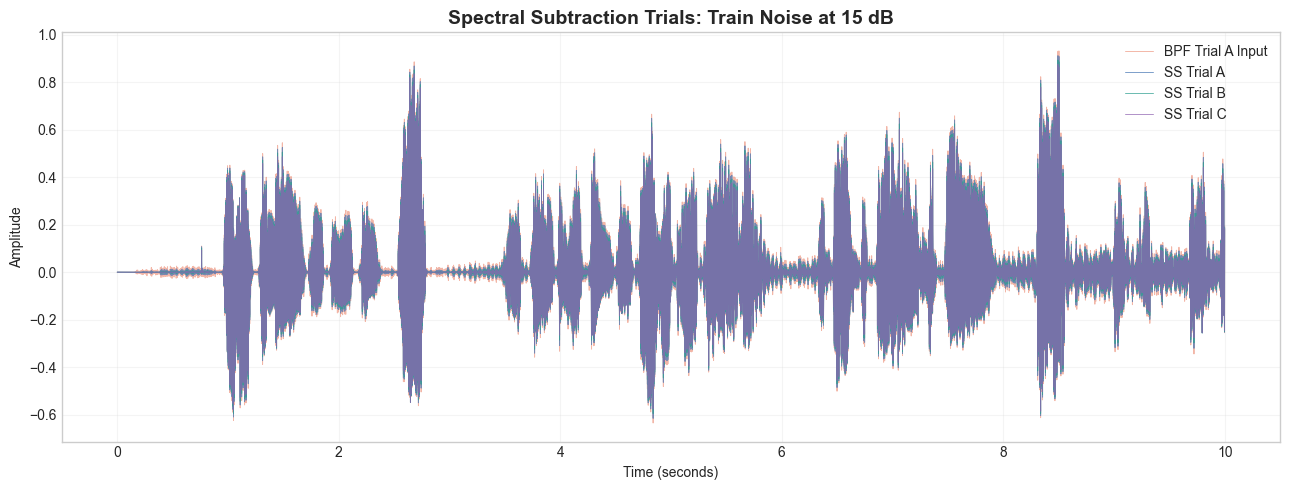

Processed: CEB006-train-15dB-BPF-TrialA.wav
Saved figure: spectral-subtraction\CEB006-train-15dB-SS-overlay.png
-------------------------------------------------------


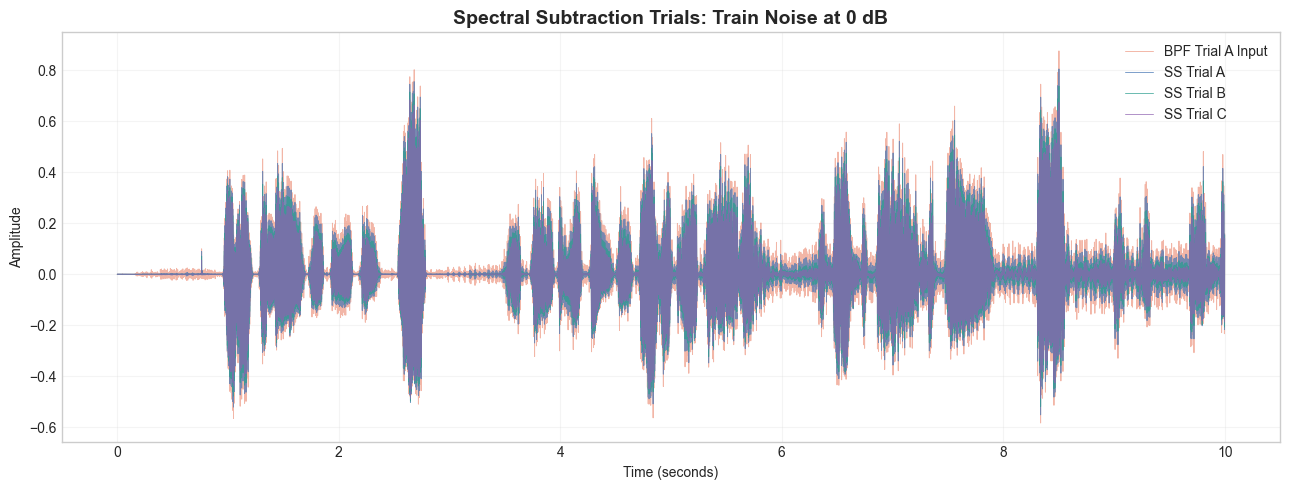

Processed: CEB006-train-0dB-BPF-TrialA.wav
Saved figure: spectral-subtraction\CEB006-train-0dB-SS-overlay.png
-------------------------------------------------------


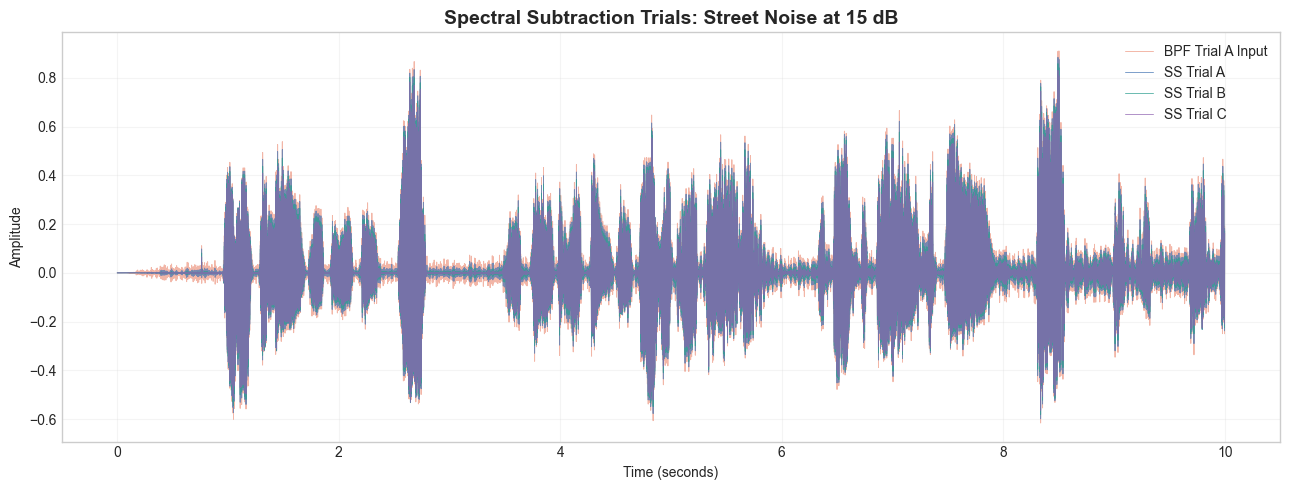

Processed: CEB006-street-15dB-BPF-TrialA.wav
Saved figure: spectral-subtraction\CEB006-street-15dB-SS-overlay.png
-------------------------------------------------------


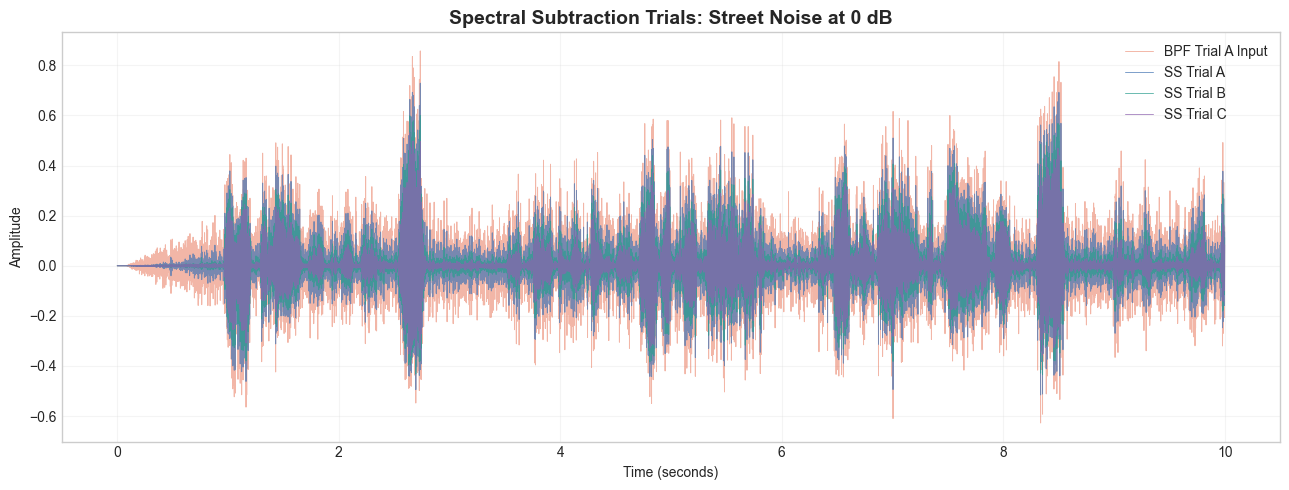

Processed: CEB006-street-0dB-BPF-TrialA.wav
Saved figure: spectral-subtraction\CEB006-street-0dB-SS-overlay.png
-------------------------------------------------------


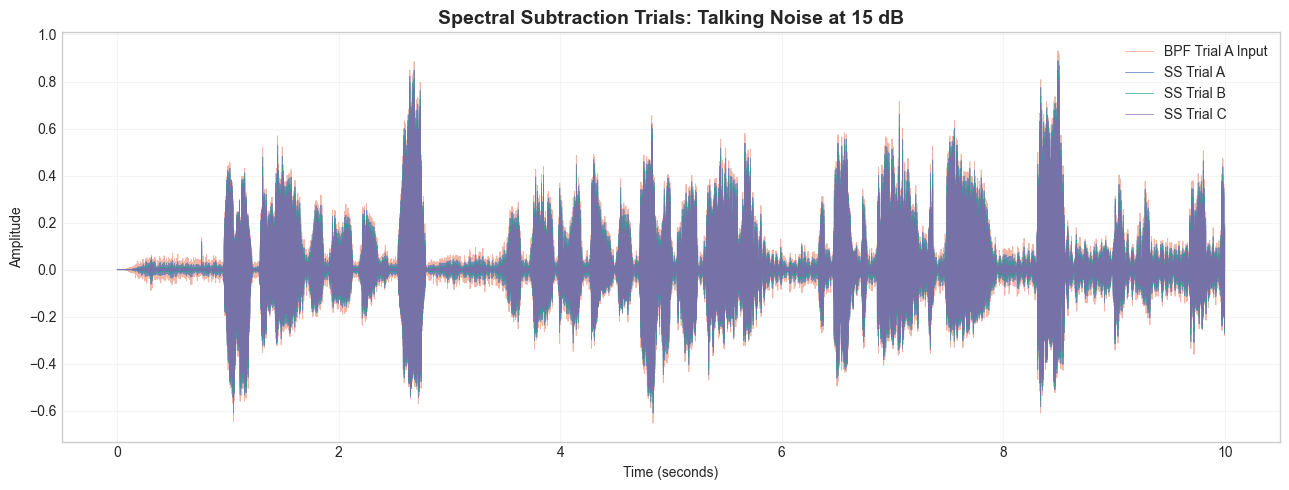

Processed: CEB006-talking-15dB-BPF-TrialA.wav
Saved figure: spectral-subtraction\CEB006-talking-15dB-SS-overlay.png
-------------------------------------------------------


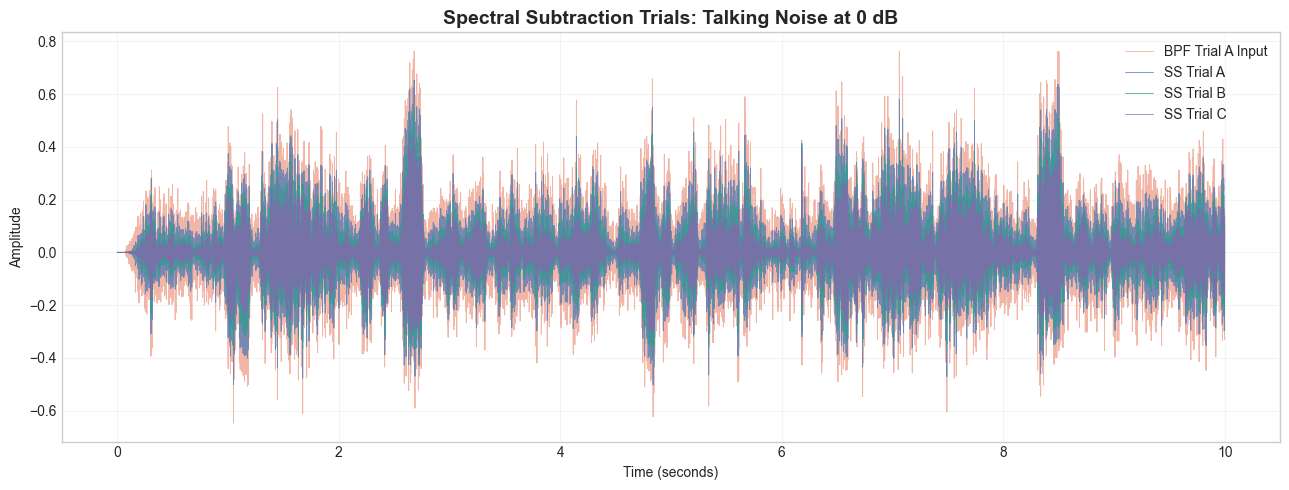

Processed: CEB006-talking-0dB-BPF-TrialA.wav
Saved figure: spectral-subtraction\CEB006-talking-0dB-SS-overlay.png
-------------------------------------------------------

SPECTRAL SUBTRACTION TRIAL RESULTS
Noise Type  SNR (dB) Trial  Alpha  Beta  RMS Change (dB)  Output Peak
     train        15     A    1.0  0.05          -0.4205       0.9456
     train        15     B    2.0  0.05          -0.8365       0.9247
     train        15     C    3.0  0.05          -1.2505       0.9048
     train         0     A    1.0  0.05          -1.2841       0.8470
     train         0     B    2.0  0.05          -2.5248       0.7741
     train         0     C    3.0  0.05          -3.7116       0.7010
    street        15     A    1.0  0.05          -0.6952       0.9150
    street        15     B    2.0  0.05          -1.3741       0.8816
    street        15     C    3.0  0.05          -2.0463       0.8488
    street         0     A    1.0  0.05          -2.8144       0.7547
    street         0    

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import stft, istft
from pathlib import Path

# ==========================================================
# STEP 1: FILE LOCATIONS AND EXPERIMENTAL SETTINGS
# ==========================================================

input_folder = Path("band-pass")
output_folder = Path("spectral-subtraction")
output_folder.mkdir(parents=True, exist_ok=True)

noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

target_sr = 16000

# ----------------------------------------------------------
# TINKER HERE: SPECTRAL SUBTRACTION TRIALS
# ----------------------------------------------------------

trials = {
    "A": {"alpha": 1.0, "beta": 0.05},
    "B": {"alpha": 2.0, "beta": 0.05},
    "C": {"alpha": 3.0, "beta": 0.05}
}

# ----------------------------------------------------------
# TINKER HERE: STFT SETTINGS
# ----------------------------------------------------------

nperseg = 512
noverlap = 384

# Estimate noise using the lowest-energy frames.
# This assumes some frames are noise-dominant.
noise_percentile = 20

# ----------------------------------------------------------
# TINKER HERE: FIGURE SETTINGS
# ----------------------------------------------------------

start_time = 0
duration = 10
plot_step = 10

colors = {
    "Original BPF": "#E76F51",
    "A": "#4575B4",
    "B": "#2A9D8F",
    "C": "#8E63B0"
}

# ==========================================================
# STEP 2: LOAD AUDIO
# ==========================================================

def load_audio(path):

    if not path.exists():
        raise FileNotFoundError(
            f"Missing audio file: {path}"
        )

    audio, sr = sf.read(path, dtype="float64")

    if sr != target_sr:
        raise ValueError(
            f"{path.name} is not 16 kHz."
        )

    if audio.ndim != 1:
        raise ValueError(
            f"{path.name} must be mono."
        )

    if len(audio) == 0:
        raise ValueError(
            f"{path.name} is empty."
        )

    return audio


# ==========================================================
# STEP 3: SPECTRAL SUBTRACTION FUNCTION
# ==========================================================

def spectral_subtraction(
    audio,
    sr,
    alpha=1.0,
    beta=0.05,
    nperseg=512,
    noverlap=384,
    noise_percentile=20
):

    # Convert audio to frequency domain
    frequencies, times, Zxx = stft(
        audio,
        fs=sr,
        nperseg=nperseg,
        noverlap=noverlap
    )

    magnitude = np.abs(Zxx)
    phase = np.angle(Zxx)

    # Estimate frame energy
    frame_energy = np.mean(
        magnitude ** 2,
        axis=0
    )

    # Select low-energy frames
    threshold = np.percentile(
        frame_energy,
        noise_percentile
    )

    noise_frames = (
        frame_energy <= threshold
    )

    # Estimate noise magnitude spectrum
    noise_estimate = np.mean(
        magnitude[:, noise_frames],
        axis=1,
        keepdims=True
    )

    # Spectral subtraction with a floor
    clean_magnitude = np.maximum(
        magnitude - alpha * noise_estimate,
        beta * magnitude
    )

    # Reconstruct complex spectrum
    enhanced_Zxx = (
        clean_magnitude * np.exp(1j * phase)
    )

    # Convert back to time domain
    _, enhanced_audio = istft(
        enhanced_Zxx,
        fs=sr,
        nperseg=nperseg,
        noverlap=noverlap
    )

    # Match original length
    enhanced_audio = enhanced_audio[:len(audio)]

    return enhanced_audio


# ==========================================================
# STEP 4: PROCESS SIX BPF RECORDINGS
# ==========================================================

results = []

for noise_type in noise_types:

    for snr in snr_levels:

        input_name = (
            f"CEB006-{noise_type}-{snr}dB-BPF-TrialA.wav"
        )

        input_path = input_folder / input_name

        bpf_audio = load_audio(input_path)

        enhanced_versions = {}

        for trial_name, config in trials.items():

            enhanced = spectral_subtraction(
                bpf_audio,
                target_sr,
                alpha=config["alpha"],
                beta=config["beta"],
                nperseg=nperseg,
                noverlap=noverlap,
                noise_percentile=noise_percentile
            )

            # Prevent clipping with a common
            # output attenuation if necessary
            peak = np.max(np.abs(enhanced))

            output_gain = (
                min(1.0, 0.99 / peak)
                if peak > 0
                else 1.0
            )

            enhanced = enhanced * output_gain

            # Save enhanced audio
            output_name = (
                f"CEB006-{noise_type}-{snr}dB-"
                f"BPF-SS-Trial{trial_name}.wav"
            )

            output_path = output_folder / output_name

            sf.write(
                output_path,
                enhanced,
                target_sr,
                subtype="FLOAT"
            )

            enhanced_versions[trial_name] = enhanced

            # Calculate basic output characteristics
            input_rms = np.sqrt(
                np.mean(bpf_audio ** 2)
            )

            output_rms = np.sqrt(
                np.mean(enhanced ** 2)
            )

            results.append({
                "Noise Type": noise_type,
                "SNR (dB)": snr,
                "Trial": trial_name,
                "Alpha": config["alpha"],
                "Beta": config["beta"],
                "Input RMS": input_rms,
                "Output RMS": output_rms,
                "RMS Change (dB)": (
                    20 * np.log10(
                        max(output_rms, 1e-12) /
                        max(input_rms, 1e-12)
                    )
                ),
                "Output Peak": np.max(
                    np.abs(enhanced)
                ),
                "Output Gain": output_gain,
                "Output File": output_name
            })

        # ==================================================
        # STEP 5: CREATE OVERLAY COMPARISON
        # ==================================================

        start = int(start_time * target_sr)
        end = min(
            int((start_time + duration) * target_sr),
            len(bpf_audio)
        )

        if end <= start:
            raise ValueError("Invalid plot interval.")

        time = np.arange(start, end) / target_sr

        fig, ax = plt.subplots(figsize=(13, 5))

        ax.plot(
            time[::plot_step],
            bpf_audio[start:end:plot_step],
            color=colors["Original BPF"],
            alpha=0.5,
            linewidth=0.7,
            label="BPF Trial A Input"
        )

        for trial_name, enhanced in enhanced_versions.items():

            ax.plot(
                time[::plot_step],
                enhanced[start:end:plot_step],
                color=colors[trial_name],
                alpha=0.7,
                linewidth=0.7,
                label=f"SS Trial {trial_name}"
            )

        ax.set_title(
            f"Spectral Subtraction Trials: "
            f"{noise_type.title()} Noise at {snr} dB",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")
        ax.legend()
        ax.grid(alpha=0.2)

        fig.tight_layout()

        figure_path = output_folder / (
            f"CEB006-{noise_type}-{snr}dB-SS-overlay.png"
        )

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        plt.show()
        plt.close(fig)

        print(f"Processed: {input_name}")
        print(f"Saved figure: {figure_path}")
        print("-" * 55)

# ==========================================================
# STEP 6: EXPORT RESULTS
# ==========================================================

df_results = pd.DataFrame(results)

print("\nSPECTRAL SUBTRACTION TRIAL RESULTS")
print("=" * 90)

print(
    df_results[
        [
            "Noise Type",
            "SNR (dB)",
            "Trial",
            "Alpha",
            "Beta",
            "RMS Change (dB)",
            "Output Peak"
        ]
    ].round(4).to_string(index=False)
)

df_results.to_csv(
    output_folder / "spectral_subtraction_results.csv",
    index=False
)

# ==========================================================
# STEP 7: SUMMARIZE BY TRIAL
# ==========================================================

summary = (
    df_results.groupby("Trial")
    .agg(
        Mean_RMS_Change_dB=("RMS Change (dB)", "mean"),
        Mean_Output_Peak=("Output Peak", "mean")
    )
    .reset_index()
)

print("\nAVERAGE RESULTS BY TRIAL")
print("=" * 65)
print(summary.round(4).to_string(index=False))

summary.to_csv(
    output_folder / "spectral_subtraction_summary.csv",
    index=False
)

print("\nSpectral Subtraction processing completed!")
print("Output folder:", output_folder.resolve())


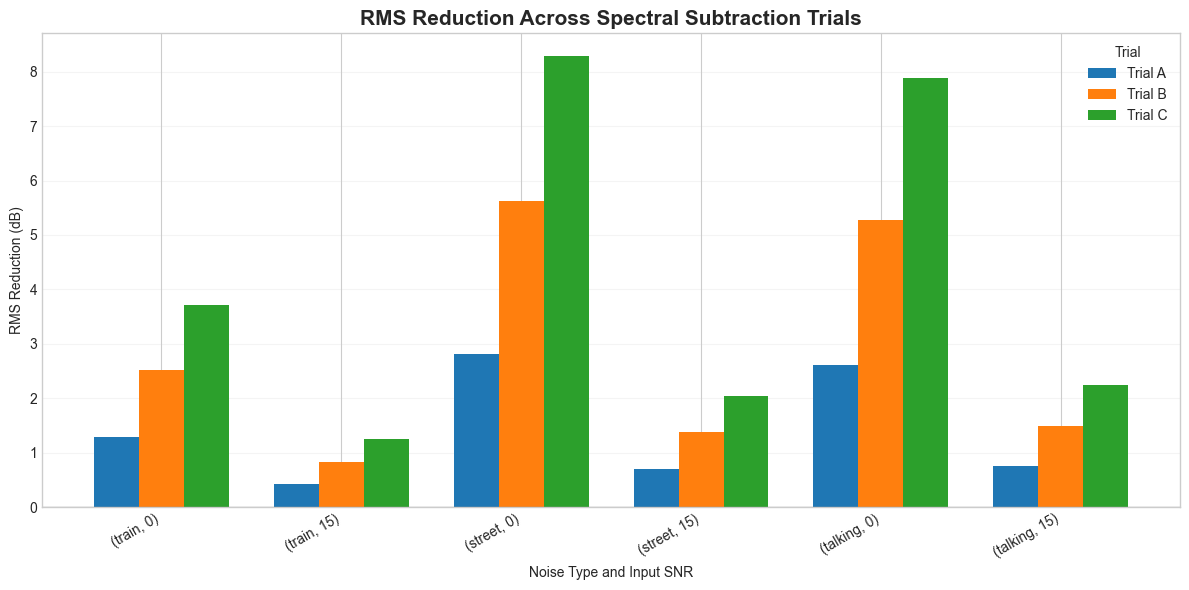

Saved to: D:\digisig\final project\ceb_audio\spectral-subtraction\SS_RMS_comparison.png


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# STEP 1: LOAD SPECTRAL SUBTRACTION RESULTS
# ==================================================

folder = Path("spectral-subtraction")

df = pd.read_csv(
    folder / "spectral_subtraction_results.csv"
)

# ==================================================
# STEP 2: SETTINGS YOU CAN TINKER WITH
# ==================================================

# Trial colors
colors = {
    "A": "#1f77b4",  # Blue
    "B": "#ff7f0e",  # Orange
    "C": "#2ca02c"   # Green
}

figure_size = (12, 6)

# ==================================================
# STEP 3: ORGANIZE RESULTS
# ==================================================

noise_order = ["train", "street", "talking"]
snr_order = [0, 15]
trial_order = ["A", "B", "C"]

conditions = [
    (noise, snr)
    for noise in noise_order
    for snr in snr_order
]

labels = [
    f"({noise}, {snr})"
    for noise, snr in conditions
]

x = np.arange(len(conditions))
bar_width = 0.25

# ==================================================
# STEP 4: CREATE BAR CHART
# ==================================================

fig, ax = plt.subplots(figsize=figure_size)

for i, trial in enumerate(trial_order):

    values = []

    for noise, snr in conditions:

        row = df[
            (df["Noise Type"] == noise) &
            (df["SNR (dB)"] == snr) &
            (df["Trial"] == trial)
        ]

        if len(row) != 1:
            raise ValueError(
                f"Missing or duplicate result: "
                f"{noise}, {snr} dB, Trial {trial}"
            )

        values.append(
            -float(row.iloc[0]["RMS Change (dB)"])
        )

    ax.bar(
        x + (i - 1) * bar_width,
        values,
        width=bar_width,
        color=colors[trial],
        label=f"Trial {trial}"
    )

ax.set_title(
    "RMS Reduction Across Spectral Subtraction Trials",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Noise Type and Input SNR")
ax.set_ylabel("RMS Reduction (dB)")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha="right")

ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(title="Trial")

plt.tight_layout()

# ==================================================
# STEP 5: SAVE FIGURE
# ==================================================

output_path = folder / "SS_RMS_comparison.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", output_path.resolve())


**CHOOSING THE OPTIMAL THRESHOLD FOR WIENER > ROOT: TRIAL B  of SSB**

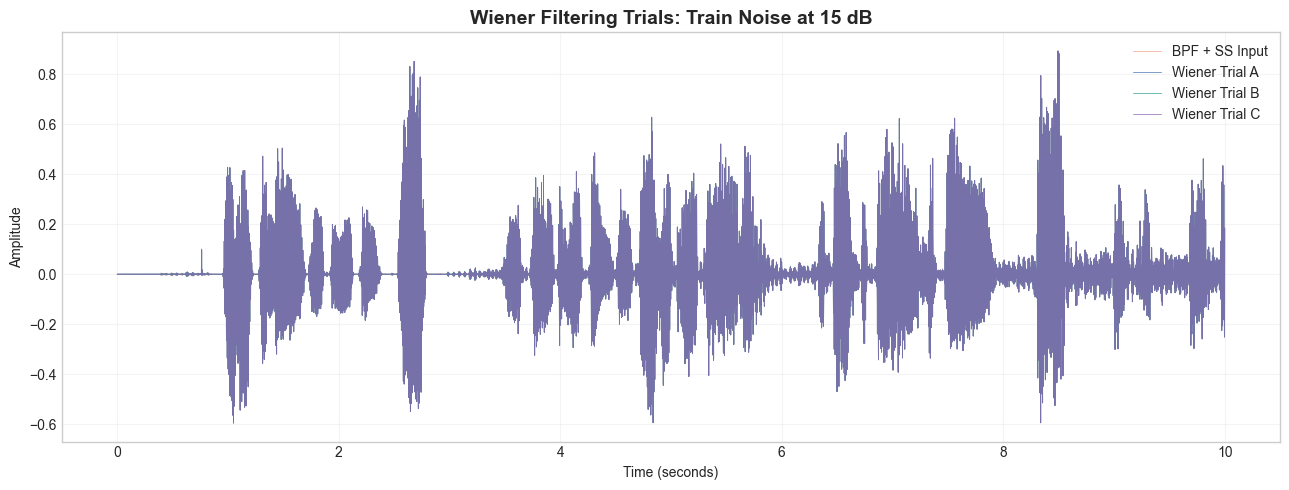

Processed: CEB006-train-15dB-BPF-SS-TrialB.wav
Saved figure: wiener-filter\CEB006-train-15dB-WF-overlay.png
-------------------------------------------------------


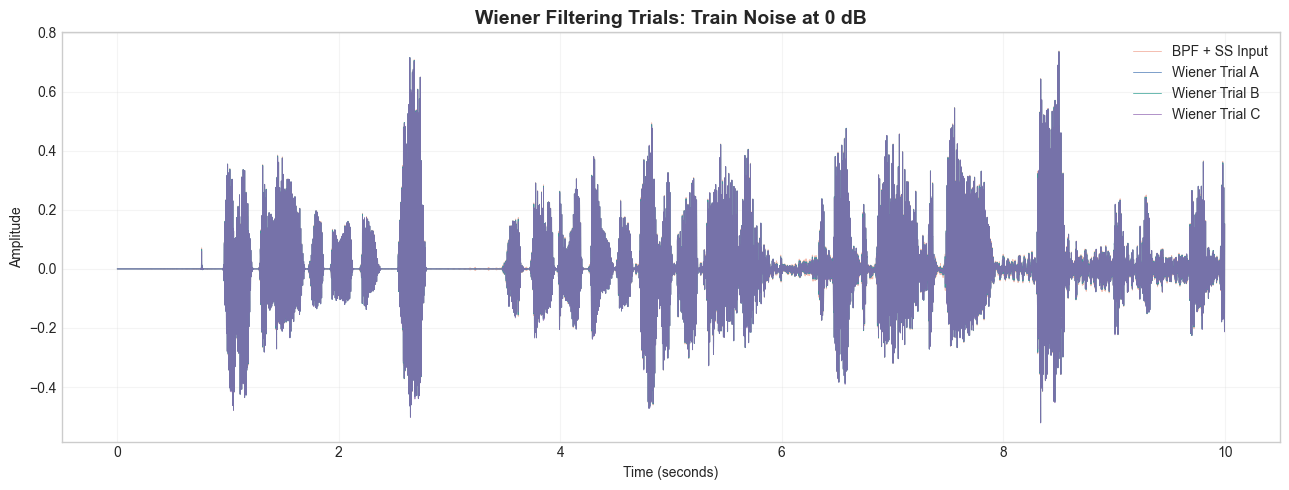

Processed: CEB006-train-0dB-BPF-SS-TrialB.wav
Saved figure: wiener-filter\CEB006-train-0dB-WF-overlay.png
-------------------------------------------------------


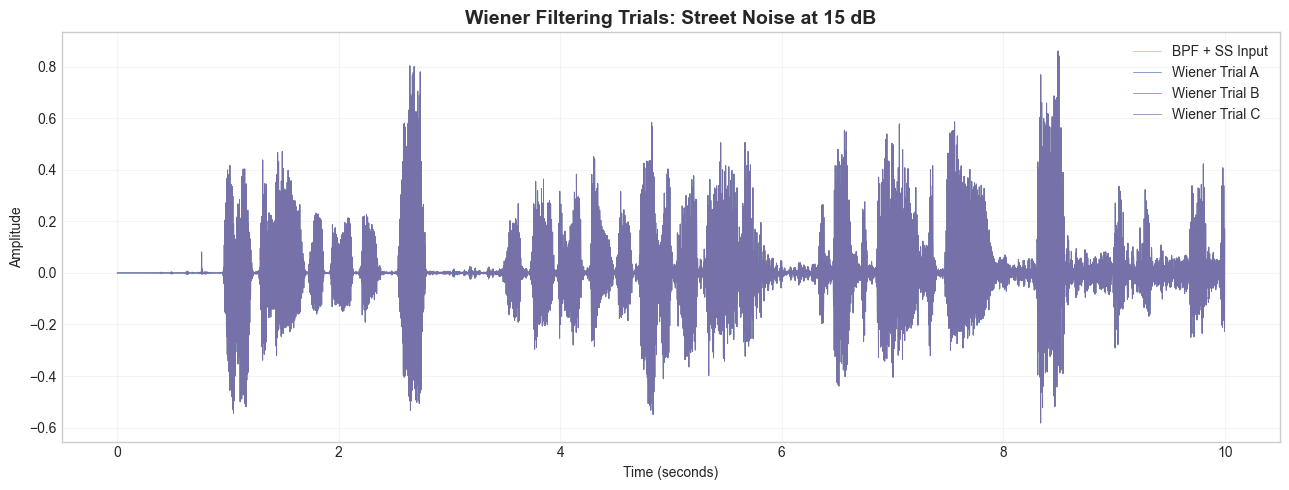

Processed: CEB006-street-15dB-BPF-SS-TrialB.wav
Saved figure: wiener-filter\CEB006-street-15dB-WF-overlay.png
-------------------------------------------------------


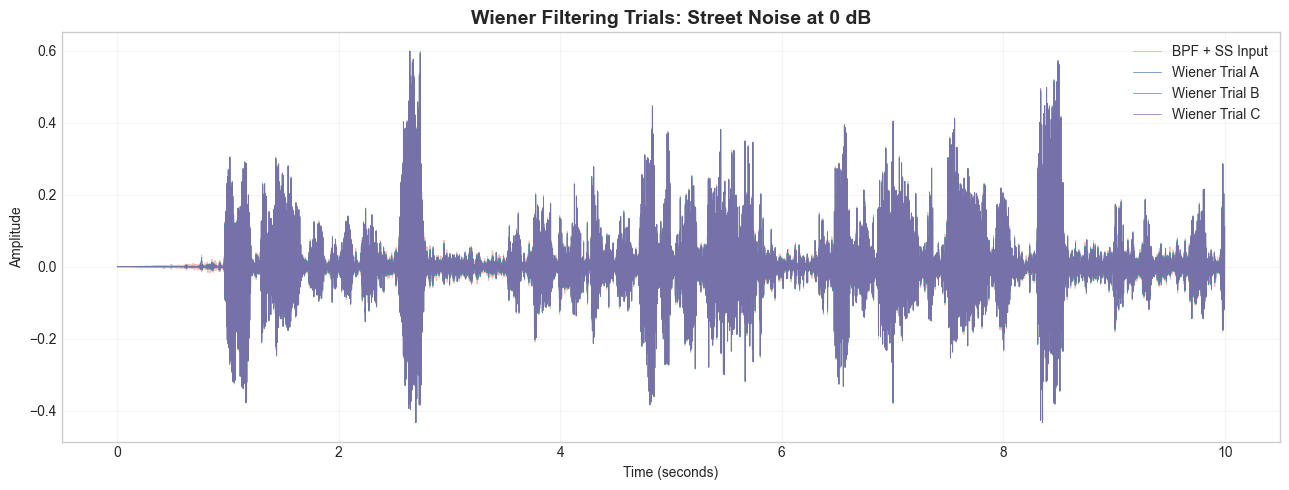

Processed: CEB006-street-0dB-BPF-SS-TrialB.wav
Saved figure: wiener-filter\CEB006-street-0dB-WF-overlay.png
-------------------------------------------------------


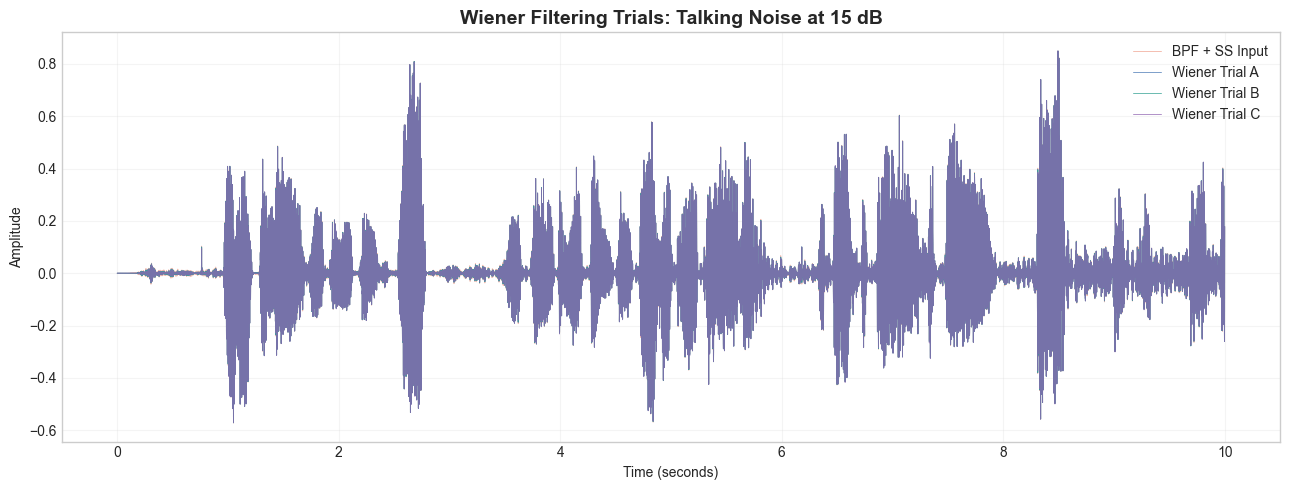

Processed: CEB006-talking-15dB-BPF-SS-TrialB.wav
Saved figure: wiener-filter\CEB006-talking-15dB-WF-overlay.png
-------------------------------------------------------


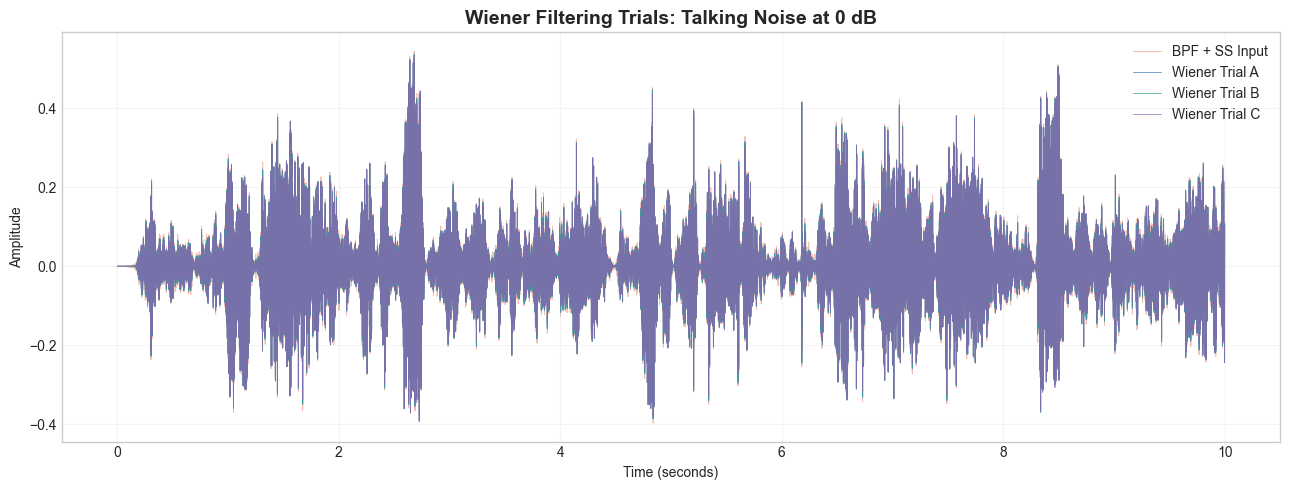

Processed: CEB006-talking-0dB-BPF-SS-TrialB.wav
Saved figure: wiener-filter\CEB006-talking-0dB-WF-overlay.png
-------------------------------------------------------

WIENER FILTER TRIAL RESULTS
Noise Type  SNR (dB) Trial  Smoothing  Gain Floor  RMS Change (dB)  Output Peak
     train        15     A       0.60        0.10          -0.0043       0.9233
     train        15     B       0.80        0.05          -0.0051       0.9230
     train        15     C       0.95        0.01          -0.0075       0.9220
     train         0     A       0.60        0.10          -0.0467       0.7730
     train         0     B       0.80        0.05          -0.0567       0.7726
     train         0     C       0.95        0.01          -0.0851       0.7709
    street        15     A       0.60        0.10          -0.0071       0.8818
    street        15     B       0.80        0.05          -0.0085       0.8819
    street        15     C       0.95        0.01          -0.0127       0.8824
    s

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import stft, istft
from pathlib import Path

# ==========================================================
# STEP 1: FILE LOCATIONS
# ==========================================================

input_folder = Path("spectral-subtraction")
output_folder = Path("wiener-filter")
output_folder.mkdir(parents=True, exist_ok=True)

noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

target_sr = 16000

# ==========================================================
# STEP 2: SETTINGS YOU CAN TINKER WITH
# ==========================================================

# Wiener Filter configurations
trials = {
    "A": {"smoothing": 0.60, "gain_floor": 0.10},
    "B": {"smoothing": 0.80, "gain_floor": 0.05},
    "C": {"smoothing": 0.95, "gain_floor": 0.01}
}

# STFT settings
nperseg = 512
noverlap = 384

# Noise estimation from low-energy frames
noise_percentile = 20

# TINKER HERE: Figure settings
start_time = 0
duration = 10
plot_step = 10

colors = {
    "Input": "#E76F51",
    "A": "#4575B4",
    "B": "#2A9D8F",
    "C": "#8E63B0"
}

# ==========================================================
# STEP 3: LOAD AUDIO
# ==========================================================

def load_audio(path):

    if not path.exists():
        raise FileNotFoundError(
            f"Missing audio file: {path}"
        )

    audio, sr = sf.read(path, dtype="float64")

    if sr != target_sr:
        raise ValueError(
            f"{path.name} is not 16 kHz."
        )

    if audio.ndim != 1:
        raise ValueError(
            f"{path.name} must be mono."
        )

    if len(audio) == 0:
        raise ValueError(
            f"{path.name} is empty."
        )

    return audio


# ==========================================================
# STEP 4: WIENER FILTER FUNCTION
# ==========================================================

def wiener_filter(
    audio,
    sr,
    smoothing=0.80,
    gain_floor=0.05,
    nperseg=512,
    noverlap=384,
    noise_percentile=20
):

    if not (0 <= smoothing < 1):
        raise ValueError("Smoothing must be in [0, 1).")

    if not (0 < gain_floor <= 1):
        raise ValueError("Gain floor must be in (0, 1].")

    # Convert audio to frequency domain
    frequencies, times, Zxx = stft(
        audio,
        fs=sr,
        nperseg=nperseg,
        noverlap=noverlap
    )

    # Calculate power spectrum
    power_spectrum = np.abs(Zxx) ** 2

    # Calculate energy for each frame
    frame_energy = np.mean(
        power_spectrum,
        axis=0
    )

    # Identify low-energy frames
    threshold = np.percentile(
        frame_energy,
        noise_percentile
    )

    noise_frames = frame_energy <= threshold

    # Estimate noise power spectrum
    noise_psd = np.mean(
        power_spectrum[:, noise_frames],
        axis=1
    )

    noise_psd = np.maximum(noise_psd, 1e-12)

    # Allocate enhanced spectrum
    enhanced_Zxx = np.zeros_like(Zxx)

    # Initialize previous gain and speech estimate
    previous_gain = np.ones(len(noise_psd))
    previous_posterior_snr = np.ones(len(noise_psd))

    # Process each time frame
    for t in range(Zxx.shape[1]):

        current_power = power_spectrum[:, t]

        # A posteriori SNR
        posterior_snr = (
            current_power / noise_psd
        )

        # Decision-directed a priori SNR
        prior_snr = (
            smoothing
            * previous_gain ** 2
            * previous_posterior_snr
            + (1 - smoothing)
            * np.maximum(posterior_snr - 1, 0)
        )

        prior_snr = np.maximum(prior_snr, 0)

        # Wiener gain
        gain = prior_snr / (1 + prior_snr)

        # Prevent complete spectral suppression
        gain = np.maximum(gain, gain_floor)

        # Apply Wiener gain
        enhanced_Zxx[:, t] = gain * Zxx[:, t]

        # Update state
        previous_gain = gain
        previous_posterior_snr = posterior_snr

    # Convert back to time domain
    _, enhanced_audio = istft(
        enhanced_Zxx,
        fs=sr,
        nperseg=nperseg,
        noverlap=noverlap
    )

    # Match original audio length
    if len(enhanced_audio) < len(audio):
        enhanced_audio = np.pad(
            enhanced_audio,
            (0, len(audio) - len(enhanced_audio))
        )

    return enhanced_audio[:len(audio)]


# ==========================================================
# STEP 5: PROCESS ALL SIX RECORDINGS
# ==========================================================

results = []

for noise_type in noise_types:

    for snr in snr_levels:

        input_name = (
            f"CEB006-{noise_type}-{snr}dB-"
            "BPF-SS-TrialB.wav"
        )

        input_path = input_folder / input_name

        audio = load_audio(input_path)

        enhanced_versions = {}

        for trial_name, config in trials.items():

            enhanced = wiener_filter(
                audio,
                target_sr,
                smoothing=config["smoothing"],
                gain_floor=config["gain_floor"],
                nperseg=nperseg,
                noverlap=noverlap,
                noise_percentile=noise_percentile
            )

            # Check output peak and prevent clipping
            peak = np.max(np.abs(enhanced))

            output_gain = (
                min(1.0, 0.99 / peak)
                if peak > 0
                else 1.0
            )

            enhanced = enhanced * output_gain

            # Save processed WAV
            output_name = (
                f"CEB006-{noise_type}-{snr}dB-"
                f"BPF-SS-WF-Trial{trial_name}.wav"
            )

            output_path = output_folder / output_name

            sf.write(
                output_path,
                enhanced,
                target_sr,
                subtype="FLOAT"
            )

            enhanced_versions[trial_name] = enhanced

            # Measure RMS change
            input_rms = np.sqrt(np.mean(audio ** 2))
            output_rms = np.sqrt(np.mean(enhanced ** 2))

            rms_change_db = 20 * np.log10(
                max(output_rms, 1e-12) /
                max(input_rms, 1e-12)
            )

            results.append({
                "Noise Type": noise_type,
                "SNR (dB)": snr,
                "Trial": trial_name,
                "Smoothing": config["smoothing"],
                "Gain Floor": config["gain_floor"],
                "RMS Change (dB)": rms_change_db,
                "Output Peak": np.max(
                    np.abs(enhanced)
                ),
                "Output Gain": output_gain,
                "Output File": output_name
            })

        # ==================================================
        # STEP 6: CREATE OVERLAY FIGURE
        # ==================================================

        start = int(start_time * target_sr)
        end = min(
            int((start_time + duration) * target_sr),
            len(audio)
        )

        if end <= start:
            raise ValueError("Invalid plot interval.")

        time = np.arange(start, end) / target_sr

        fig, ax = plt.subplots(figsize=(13, 5))

        ax.plot(
            time[::plot_step],
            audio[start:end:plot_step],
            color=colors["Input"],
            alpha=0.45,
            linewidth=0.7,
            label="BPF + SS Input"
        )

        for trial_name, enhanced in enhanced_versions.items():

            ax.plot(
                time[::plot_step],
                enhanced[start:end:plot_step],
                color=colors[trial_name],
                alpha=0.7,
                linewidth=0.7,
                label=f"Wiener Trial {trial_name}"
            )

        ax.set_title(
            f"Wiener Filtering Trials: "
            f"{noise_type.title()} Noise at {snr} dB",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")
        ax.legend()
        ax.grid(alpha=0.2)

        fig.tight_layout()

        figure_path = output_folder / (
            f"CEB006-{noise_type}-{snr}dB-"
            "WF-overlay.png"
        )

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

        print(f"Processed: {input_name}")
        print(f"Saved figure: {figure_path}")
        print("-" * 55)

# ==========================================================
# STEP 7: EXPORT RESULTS
# ==========================================================

df_results = pd.DataFrame(results)

print("\nWIENER FILTER TRIAL RESULTS")
print("=" * 90)

print(
    df_results[
        [
            "Noise Type",
            "SNR (dB)",
            "Trial",
            "Smoothing",
            "Gain Floor",
            "RMS Change (dB)",
            "Output Peak"
        ]
    ].round(4).to_string(index=False)
)

df_results.to_csv(
    output_folder / "wiener_filter_results.csv",
    index=False
)

# ==========================================================
# STEP 8: SUMMARIZE BY TRIAL
# ==========================================================

summary = (
    df_results.groupby("Trial")
    .agg(
        Mean_RMS_Change_dB=("RMS Change (dB)", "mean"),
        Mean_Output_Peak=("Output Peak", "mean")
    )
    .reset_index()
)

print("\nAVERAGE RESULTS BY TRIAL")
print("=" * 65)
print(summary.round(4).to_string(index=False))

summary.to_csv(
    output_folder / "wiener_filter_summary.csv",
    index=False
)

print("\nWiener Filtering completed!")
print("Output folder:", output_folder.resolve())


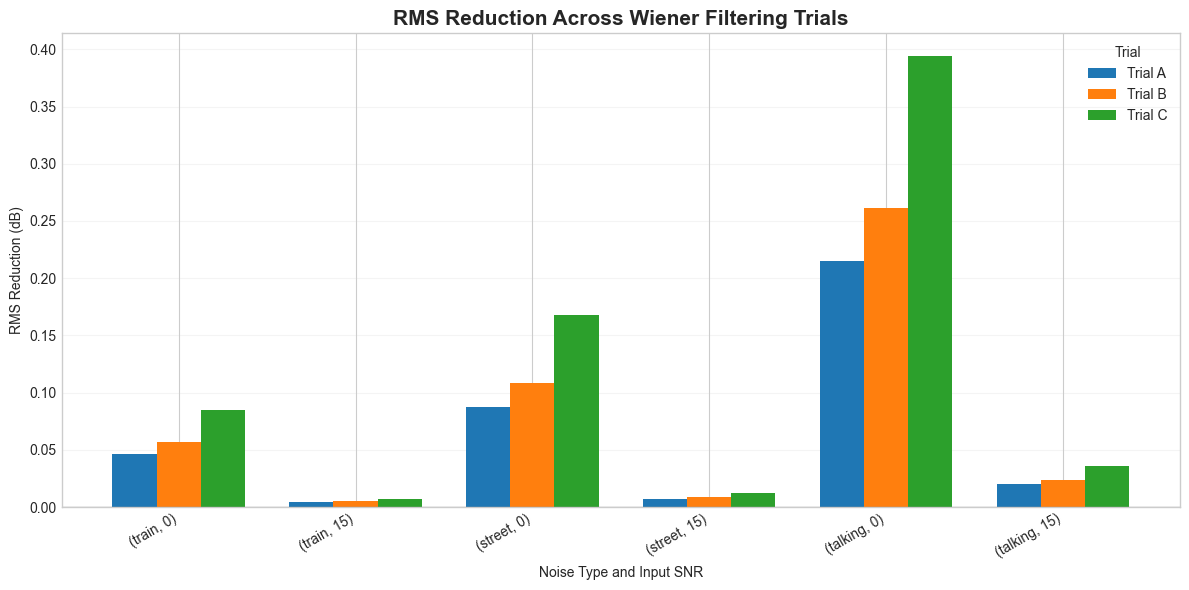

Saved to: D:\digisig\final project\ceb_audio\wiener-filter\WF_RMS_comparison.png


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# STEP 1: LOAD WIENER FILTER RESULTS
# ==================================================

folder = Path("wiener-filter")

df = pd.read_csv(
    folder / "wiener_filter_results.csv"
)

# ==================================================
# STEP 2: SETTINGS YOU CAN TINKER WITH
# ==================================================

colors = {
    "A": "#1f77b4",  # Blue
    "B": "#ff7f0e",  # Orange
    "C": "#2ca02c"   # Green
}

figure_size = (12, 6)

# ==================================================
# STEP 3: ORGANIZE RESULTS
# ==================================================

noise_order = ["train", "street", "talking"]
snr_order = [0, 15]
trial_order = ["A", "B", "C"]

conditions = [
    (noise, snr)
    for noise in noise_order
    for snr in snr_order
]

labels = [
    f"({noise}, {snr})"
    for noise, snr in conditions
]

x = np.arange(len(conditions))
bar_width = 0.25

# ==================================================
# STEP 4: CREATE BAR CHART
# ==================================================

fig, ax = plt.subplots(figsize=figure_size)

for i, trial in enumerate(trial_order):

    values = []

    for noise, snr in conditions:

        row = df[
            (df["Noise Type"] == noise) &
            (df["SNR (dB)"] == snr) &
            (df["Trial"] == trial)
        ]

        if len(row) != 1:
            raise ValueError(
                f"Missing or duplicate result: "
                f"{noise}, {snr} dB, Trial {trial}"
            )

        values.append(
            -float(row.iloc[0]["RMS Change (dB)"])
        )

    ax.bar(
        x + (i - 1) * bar_width,
        values,
        width=bar_width,
        color=colors[trial],
        label=f"Trial {trial}"
    )

ax.set_title(
    "RMS Reduction Across Wiener Filtering Trials",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Noise Type and Input SNR")
ax.set_ylabel("RMS Reduction (dB)")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha="right")

ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(title="Trial")

plt.tight_layout()

# ==================================================
# STEP 5: SAVE FIGURE
# ==================================================

output_path = folder / "WF_RMS_comparison.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", output_path.resolve())



REFERENCE-BASED SNR COMPARISON
Noise Type  Target SNR (dB)         Stage  Reference Residual Ratio (dB)  Alignment Gain
     train               15      Baseline                         15.003           0.974
     train               15           BPF                         13.331           0.829
     train               15      BPF + SS                         11.624           0.745
     train               15 BPF + SS + WF                         11.591           0.745
     train                0      Baseline                          0.016           0.885
     train                0           BPF                          7.331           0.752
     train                0      BPF + SS                          7.518           0.564
     train                0 BPF + SS + WF                          7.538           0.562
    street               15      Baseline                         14.996           0.954
    street               15           BPF                         11.423      

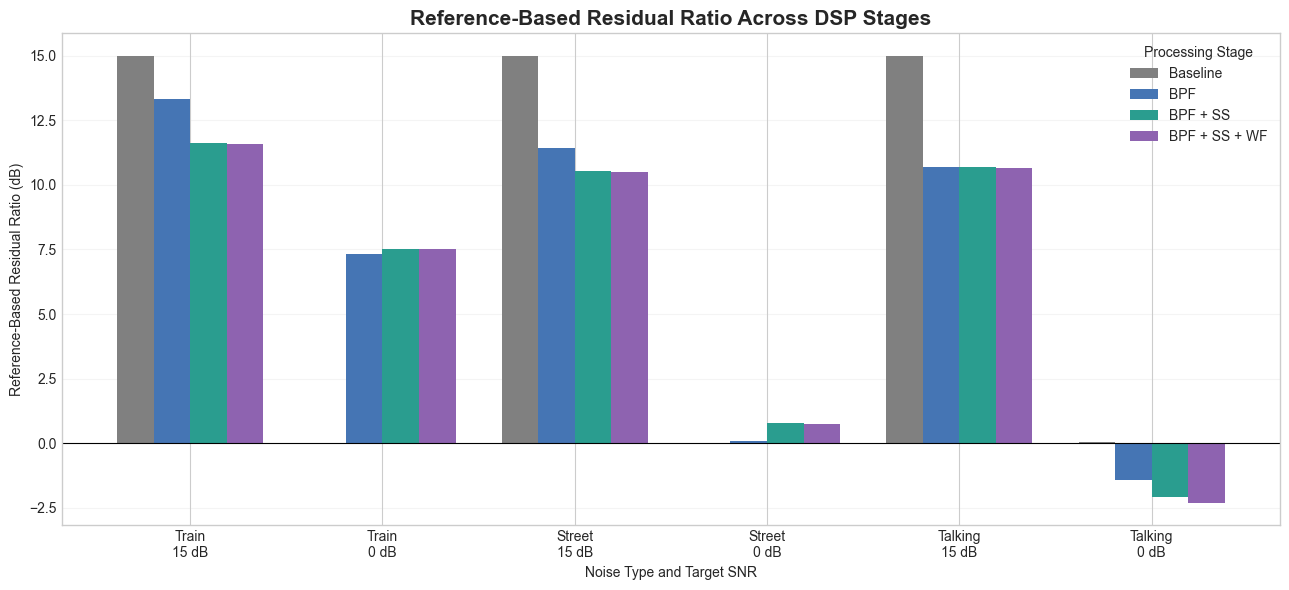


Saved figure: D:\digisig\final project\ceb_audio\snr-evaluation\DSP_stage_SNR_comparison.png

CHANGE RELATIVE TO BASELINE
Stage                          BPF  BPF + SS  BPF + SS + WF  Baseline  BPF Change (dB)  BPF + SS Change (dB)  BPF + SS + WF Change (dB)
Noise Type Target SNR (dB)                                                                                                             
street     0                 0.080     0.791          0.743    -0.023            0.104                 0.815                      0.766
           15               11.423    10.541         10.512    14.996           -3.573                -4.455                     -4.484
talking    0                -1.438    -2.100         -2.322     0.042           -1.479                -2.142                     -2.363
           15               10.691    10.699         10.663    15.008           -4.317                -4.309                     -4.345
train      0                 7.331     7.518          7.538  

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# STEP 1: FILE LOCATIONS
# ==================================================

reference_path = Path(
    "standardized_audio/CEB_006_lowest_duration_standardized.wav"
)

folders = {
    "Baseline": Path("augmented_audio"),
    "BPF": Path("band-pass"),
    "BPF + SS": Path("spectral-subtraction"),
    "BPF + SS + WF": Path("wiener-filter")
}

noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

output_folder = Path("snr-evaluation")
output_folder.mkdir(parents=True, exist_ok=True)

# ==================================================
# STEP 2: SETTINGS YOU CAN TINKER WITH
# ==================================================

colors = {
    "Baseline": "#808080",
    "BPF": "#4575B4",
    "BPF + SS": "#2A9D8F",
    "BPF + SS + WF": "#8E63B0"
}

stage_order = [
    "Baseline",
    "BPF",
    "BPF + SS",
    "BPF + SS + WF"
]

# ==================================================
# STEP 3: LOAD AUDIO
# ==================================================

def load_audio(path):

    if not path.exists():
        raise FileNotFoundError(
            f"Missing audio: {path}"
        )

    audio, sr = sf.read(path, dtype="float64")

    if sr != 16000 or audio.ndim != 1:
        raise ValueError(
            f"{path.name} must be 16 kHz mono."
        )

    return audio


reference = load_audio(reference_path)

# ==================================================
# STEP 4: REFERENCE-BASED RESIDUAL RATIO
# ==================================================

def reference_residual_ratio(reference, processed):

    if len(reference) != len(processed):
        raise ValueError("Audio lengths do not match.")

    # Estimate best-fit scalar gain
    gain = np.dot(reference, processed) / (
        np.dot(reference, reference) + 1e-12
    )

    aligned_reference = gain * reference

    residual = processed - aligned_reference

    signal_power = np.mean(aligned_reference ** 2)
    residual_power = np.mean(residual ** 2)

    ratio = 10 * np.log10(
        (signal_power + 1e-12) /
        (residual_power + 1e-12)
    )

    return ratio, gain


# ==================================================
# STEP 5: COMPARE ALL SIX CONDITIONS
# ==================================================

results = []

for noise in noise_types:

    for snr in snr_levels:

        filenames = {
            "Baseline": (
                f"CEB_006_{noise}_{snr}dB.wav"
            ),
            "BPF": (
                f"CEB006-{noise}-{snr}dB-"
                "BPF-TrialA.wav"
            ),
            "BPF + SS": (
                f"CEB006-{noise}-{snr}dB-"
                "BPF-SS-TrialB.wav"
            ),
            "BPF + SS + WF": (
                f"CEB006-{noise}-{snr}dB-"
                "BPF-SS-WF-TrialA.wav"
            )
        }

        for stage in stage_order:

            path = folders[stage] / filenames[stage]

            processed = load_audio(path)

            ratio, gain = reference_residual_ratio(
                reference,
                processed
            )

            results.append({
                "Noise Type": noise,
                "Target SNR (dB)": snr,
                "Stage": stage,
                "Reference Residual Ratio (dB)": ratio,
                "Alignment Gain": gain
            })

# ==================================================
# STEP 6: DISPLAY AND EXPORT RESULTS
# ==================================================

df = pd.DataFrame(results)

print("\nREFERENCE-BASED SNR COMPARISON")
print("=" * 85)

print(
    df.round(3).to_string(index=False)
)

df.to_csv(
    output_folder / "snr_stage_comparison.csv",
    index=False
)

# ==================================================
# STEP 7: CREATE GROUPED BAR CHART
# ==================================================

conditions = [
    (noise, snr)
    for noise in noise_types
    for snr in snr_levels
]

labels = [
    f"{noise.title()}\n{snr} dB"
    for noise, snr in conditions
]

x = np.arange(len(conditions))
width = 0.19

fig, ax = plt.subplots(figsize=(13, 6))

for i, stage in enumerate(stage_order):

    values = []

    for noise, snr in conditions:

        row = df[
            (df["Noise Type"] == noise) &
            (df["Target SNR (dB)"] == snr) &
            (df["Stage"] == stage)
        ]

        values.append(
            float(
                row.iloc[0][
                    "Reference Residual Ratio (dB)"
                ]
            )
        )

    ax.bar(
        x + (i - 1.5) * width,
        values,
        width=width,
        label=stage,
        color=colors[stage]
    )

ax.set_title(
    "Reference-Based Residual Ratio Across DSP Stages",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Noise Type and Target SNR")
ax.set_ylabel("Reference-Based Residual Ratio (dB)")

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.axhline(0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(title="Processing Stage")

plt.tight_layout()

figure_path = (
    output_folder / "DSP_stage_SNR_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure:", figure_path.resolve())

# ==================================================
# STEP 8: CALCULATE CHANGE RELATIVE TO BASELINE
# ==================================================

pivot = df.pivot_table(
    index=["Noise Type", "Target SNR (dB)"],
    columns="Stage",
    values="Reference Residual Ratio (dB)"
)

for stage in stage_order[1:]:
    pivot[f"{stage} Change (dB)"] = (
        pivot[stage] - pivot["Baseline"]
    )

print("\nCHANGE RELATIVE TO BASELINE")
print("=" * 85)

print(pivot.round(3).to_string())

pivot.to_csv(
    output_folder / "DSP_stage_improvement.csv"
)


**WORD-ERROR-RATE TESTING**

LOADING THE MODEL

In [ ]:

import torch
from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration
)

# Cebuano fine-tuned Whisper Small
model_id = "sapinsapin/whisper-small-pld-ceb"

# Use GPU if available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

# Download and load processor
processor = WhisperProcessor.from_pretrained(model_id)

# Download and load model
model = WhisperForConditionalGeneration.from_pretrained(
    model_id
)

model = model.to(device)
model.eval()

print("Whisper Small Cebuano model loaded successfully!")


Using device: cpu


c:\Users\casper\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\casper\.cache\huggingface\hub\models--sapinsapin--whisper-small-pld-ceb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 479/479 [00:01<00:00, 349.72it/s]


Whisper Small Cebuano model loaded successfully!


AUGMENTED AUDIO (WHISPER AI)

In [ ]:

import soundfile as sf
import numpy as np

# Load one augmented recording
audio_path = "augmented_audio/CEB_006_train_15dB.wav"

audio, sr = sf.read(audio_path)

if sr != 16000:
    raise ValueError("Audio must be sampled at 16,000 Hz.")

if audio.ndim != 1:
    raise ValueError("Audio must be mono.")

# Whisper processes audio in approximately 30-second windows.
# Use the first 25 seconds for our initial test.
audio = audio[:25 * sr]

# Convert audio to model inputs
inputs = processor(
    audio,
    sampling_rate=sr,
    return_tensors="pt"
)

input_features = inputs.input_features.to(device)

# Generate transcription
with torch.inference_mode():
    predicted_ids = model.generate(
        input_features,
        task="transcribe",
        max_new_tokens=225
    )

# Decode transcription
transcription = processor.batch_decode(
    predicted_ids,
    skip_special_tokens=True
)[0]

print("\nCEBUANO TRANSCRIPTION")
print("-" * 50)
print(transcription)


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



CEBUANO TRANSCRIPTION
--------------------------------------------------
Naa ka baay anting-anting? Wala. Wala kay anting-anting kay kaning-anting-anting manggod, usa ni siya ka dakong sala sa Christianismo kay anting-anting manggod, borag nisalig ka sa imohang anting-anting kay sa sa imohang Ginuo nga imong Diyos. Kaning-anting-anting kay gibuhat ni siya sa yawa nga motintal bitaw nga kani ang imong saligat kay namo sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang nahipatidong sa iyang


PROCESSED AUDIO (WHISPER AI)

In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import re

from pathlib import Path
from jiwer import wer

# ==================================================
# STEP 1: FILE LOCATIONS
# ==================================================

reference_path = Path("CEB_006_reference.txt")

baseline_folder = Path("augmented_audio")
enhanced_folder = Path("wiener-filter")

output_folder = Path("wer-evaluation")
output_folder.mkdir(parents=True, exist_ok=True)

noise_types = ["train", "street", "talking"]
snr_levels = [15, 0]

# ==================================================
# STEP 2: LOAD REFERENCE TRANSCRIPTION
# ==================================================

reference = reference_path.read_text(
    encoding="utf-8"
).strip()

# ==================================================
# STEP 3: NORMALIZE TEXT
# ==================================================

def normalize_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    return " ".join(text.split())

reference_normalized = normalize_text(reference)

# ==================================================
# STEP 4: TRANSCRIPTION FUNCTION
# ==================================================

def transcribe_audio(audio_path):

    audio, sr = sf.read(
        audio_path,
        dtype="float32"
    )

    if sr != 16000 or audio.ndim != 1:
        raise ValueError(
            f"{audio_path.name} must be 16 kHz mono."
        )

    # Process the entire CEB_006 recording.
    # Whisper accepts approximately 30-second windows.
    # Split longer recordings into segments.
    chunk_samples = 25 * sr

    transcripts = []

    for start in range(0, len(audio), chunk_samples):

        chunk = audio[
            start:start + chunk_samples
        ]

        inputs = processor(
            chunk,
            sampling_rate=sr,
            return_tensors="pt"
        )

        input_features = (
            inputs.input_features.to(device)
        )

        with torch.inference_mode():
            predicted_ids = model.generate(
                input_features,
                task="transcribe",
                max_new_tokens=225
            )

        text = processor.batch_decode(
            predicted_ids,
            skip_special_tokens=True
        )[0]

        transcripts.append(text.strip())

    return " ".join(transcripts).strip()

# ==================================================
# STEP 5: EVALUATE BASELINE AND ENHANCED AUDIO
# ==================================================

results = []

for noise in noise_types:

    for snr in snr_levels:

        files = {
            "Baseline": (
                baseline_folder /
                f"CEB_006_{noise}_{snr}dB.wav"
            ),
            "BPF + SS + WF": (
                enhanced_folder /
                f"CEB006-{noise}-{snr}dB-"
                "BPF-SS-WF-TrialA.wav"
            )
        }

        for stage, path in files.items():

            if not path.exists():
                raise FileNotFoundError(path)

            print(f"Transcribing: {path.name}")

            transcription = transcribe_audio(path)

            # Calculate WER
            predicted_normalized = normalize_text(
                transcription
            )

            wer_score = wer(
                reference_normalized,
                predicted_normalized
            ) * 100

            # Save transcription
            transcript_name = (
                f"CEB006-{noise}-{snr}dB-"
                f"{stage.replace(' ', '_').replace('+', '')}.txt"
            )

            (
                output_folder / transcript_name
            ).write_text(
                transcription,
                encoding="utf-8"
            )

            results.append({
                "Noise Type": noise,
                "SNR (dB)": snr,
                "Stage": stage,
                "WER (%)": round(wer_score, 2),
                "Transcription": transcription
            })

            print(f"WER: {wer_score:.2f}%")
            print("-" * 55)

# ==================================================
# STEP 6: EXPORT RESULTS
# ==================================================

df_results = pd.DataFrame(results)

print("\nWER EVALUATION RESULTS")
print("=" * 85)

print(
    df_results[
        ["Noise Type", "SNR (dB)", "Stage", "WER (%)"]
    ].to_string(index=False)
)

df_results.to_csv(
    output_folder / "WER_results.csv",
    index=False
)

# ==================================================
# STEP 7: COMPARE BASELINE VS ENHANCED
# ==================================================

comparison = df_results.pivot_table(
    index=["Noise Type", "SNR (dB)"],
    columns="Stage",
    values="WER (%)"
)

comparison["WER Improvement (pp)"] = (
    comparison["Baseline"] -
    comparison["BPF + SS + WF"]
)

print("\nBASELINE VS ENHANCED WER")
print("=" * 85)

print(comparison.round(2).to_string())

comparison.to_csv(
    output_folder / "WER_comparison.csv"
)

print("\nWER evaluation completed!")
print("Results saved to:", output_folder.resolve())


Transcribing: CEB_006_train_15dB.wav


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


WER: 82.43%
-------------------------------------------------------
Transcribing: CEB006-train-15dB-BPF-SS-WF-TrialA.wav


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


WER: 90.54%
-------------------------------------------------------
Transcribing: CEB_006_train_0dB.wav


...

WER: 122.97%
-------------------------------------------------------
Transcribing: CEB_006_talking_0dB.wav


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


WER: 275.68%
-------------------------------------------------------
Transcribing: CEB006-talking-0dB-BPF-SS-WF-TrialA.wav


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


WER: 194.59%
-------------------------------------------------------

WER EVALUATION RESULTS
Noise Type  SNR (dB)         Stage  WER (%)
     train        15      Baseline    82.43
     train        15 BPF + SS + WF    90.54
     train         0      Baseline   118.92
     train         0 BPF + SS + WF    50.00
    street        15      Baseline   101.35
    street        15 BPF + SS + WF    37.84
    street         0      Baseline   147.30
    street         0 BPF + SS + WF    83.78
   talking        15      Baseline    39.19
   talking        15 BPF + SS + WF   122.97
   talking         0      Baseline   275.68
   talking         0 BPF + SS + WF   194.59

BASELINE VS ENHANCED WER
Stage                BPF + SS + WF  Baseline  WER Improvement (pp)
Noise Type SNR (dB)                                               
street     0                 83.78    147.30                 63.52
           15                37.84    101.35                 63.51
talking    0                194.59    275